In [1]:
import pandas as pd
import numpy as np
import random

# Set random seed for reproducibility
random.seed(42)
np.random.seed(42)

# Constants
hours_per_year = 8760
building_types = ['Hospital', 'House1', 'House2', 'Industry', 'School', 'Office']
seasons = ['Winter', 'Spring', 'Summer', 'Fall']
temperature_range = (-8, 43)  # Outdoor temperature range in °C
humidity_range = (40, 100)     # Humidity range in %
cloud_cover_range = (0, 100)   # Cloud cover range in %
occupancy_range = {
    'Hospital': (200, 400),
    'House1': (1, 4),
    'House2': (1, 4),
    'Industry': (20, 200),
    'School': (50, 500),
    'Office': (10, 100)
}
special_equipment_range = {
    'Hospital': (200, 500),
    'House1': (0, 1),
    'House2': (0, 1),
    'Industry': (20, 50),
    'School': (10, 30),
    'Office': (10, 20)
}
lighting_range = {
    'Hospital': (10, 20),
    'House1': (0, 1),
    'House2': (0, 1),
    'Industry': (1, 5),
    'School': (0, 2),
    'Office': (0, 2)
}
hvac_range = {
    'Hospital': (30, 60),
    'House1': (1, 3),
    'House2': (1, 3),
    'Industry': (5, 10),
    'School': (2, 5),
    'Office': (2, 5)
}

# Create an empty list to hold dataframes for each building
building_dfs = []

# Function to generate a dataset for each building type
def generate_building_data(building_type):
    data = {
        'Time': pd.date_range(start='2023-01-01', periods=hours_per_year, freq='H'),
        'Season': [seasons[(i // (hours_per_year // 4)) % 4] for i in range(hours_per_year)],
        'Winter': [1 if (i // (hours_per_year // 4)) % 4 == 0 else 0 for i in range(hours_per_year)],
        'Spring': [1 if (i // (hours_per_year // 4)) % 4 == 1 else 0 for i in range(hours_per_year)],
        'Summer': [1 if (i // (hours_per_year // 4)) % 4 == 2 else 0 for i in range(hours_per_year)],
        'Fall': [1 if (i // (hours_per_year // 4)) % 4 == 3 else 0 for i in range(hours_per_year)],
        'Outdoor Temp (°C)': np.random.uniform(temperature_range[0], temperature_range[1], hours_per_year),
        'Humidity (%)': np.random.uniform(humidity_range[0], humidity_range[1], hours_per_year),
        'Cloud Cover (%)': np.random.uniform(cloud_cover_range[0], cloud_cover_range[1], hours_per_year),
        'Occupancy': np.random.randint(occupancy_range[building_type][0], occupancy_range[building_type][1], hours_per_year),
        'Special Equipment [kW]': np.random.uniform(special_equipment_range[building_type][0], special_equipment_range[building_type][1], hours_per_year),
        'Lighting [kW]': np.random.uniform(lighting_range[building_type][0], lighting_range[building_type][1], hours_per_year),
        'HVAC [kW]': np.random.uniform(hvac_range[building_type][0], hvac_range[building_type][1], hours_per_year),
    }

    df = pd.DataFrame(data)
    
    # Calculate Use [kW] as a function of the other features, adding some noise for realism
    df['Use [kW]'] = (df['Special Equipment [kW]'] + df['Lighting [kW]'] + df['HVAC [kW]'] +
                      0.5 * df['Occupancy'] + 
                      np.random.normal(0, 5, hours_per_year))  # Adding noise
    
    # Remove any negative values in Use [kW]
    df['Use [kW]'] = df['Use [kW]'].clip(lower=0)
    
    # One-hot encode the season variable
    df = pd.get_dummies(df, columns=['Season'], drop_first=True)

    return df

# Generate data for each building type
for building in building_types:
    building_df = generate_building_data(building)
    building_dfs.append(building_df)

# Save each dataframe to a separate CSV file
for building, df in zip(building_types, building_dfs):
    df.to_csv(f'{building}_data.csv', index=False)

print("Datasets generated and saved successfully.")


Datasets generated and saved successfully.



EDA for Hospital Dataset
Basic Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Time                    8760 non-null   datetime64[ns]
 1   Winter                  8760 non-null   int64         
 2   Spring                  8760 non-null   int64         
 3   Summer                  8760 non-null   int64         
 4   Fall                    8760 non-null   int64         
 5   Outdoor Temp (°C)       8760 non-null   float64       
 6   Humidity (%)            8760 non-null   float64       
 7   Cloud Cover (%)         8760 non-null   float64       
 8   Occupancy               8760 non-null   int64         
 9   Special Equipment [kW]  8760 non-null   float64       
 10  Lighting [kW]           8760 non-null   float64       
 11  HVAC [kW]               8760 non-null   float64       
 12  Use

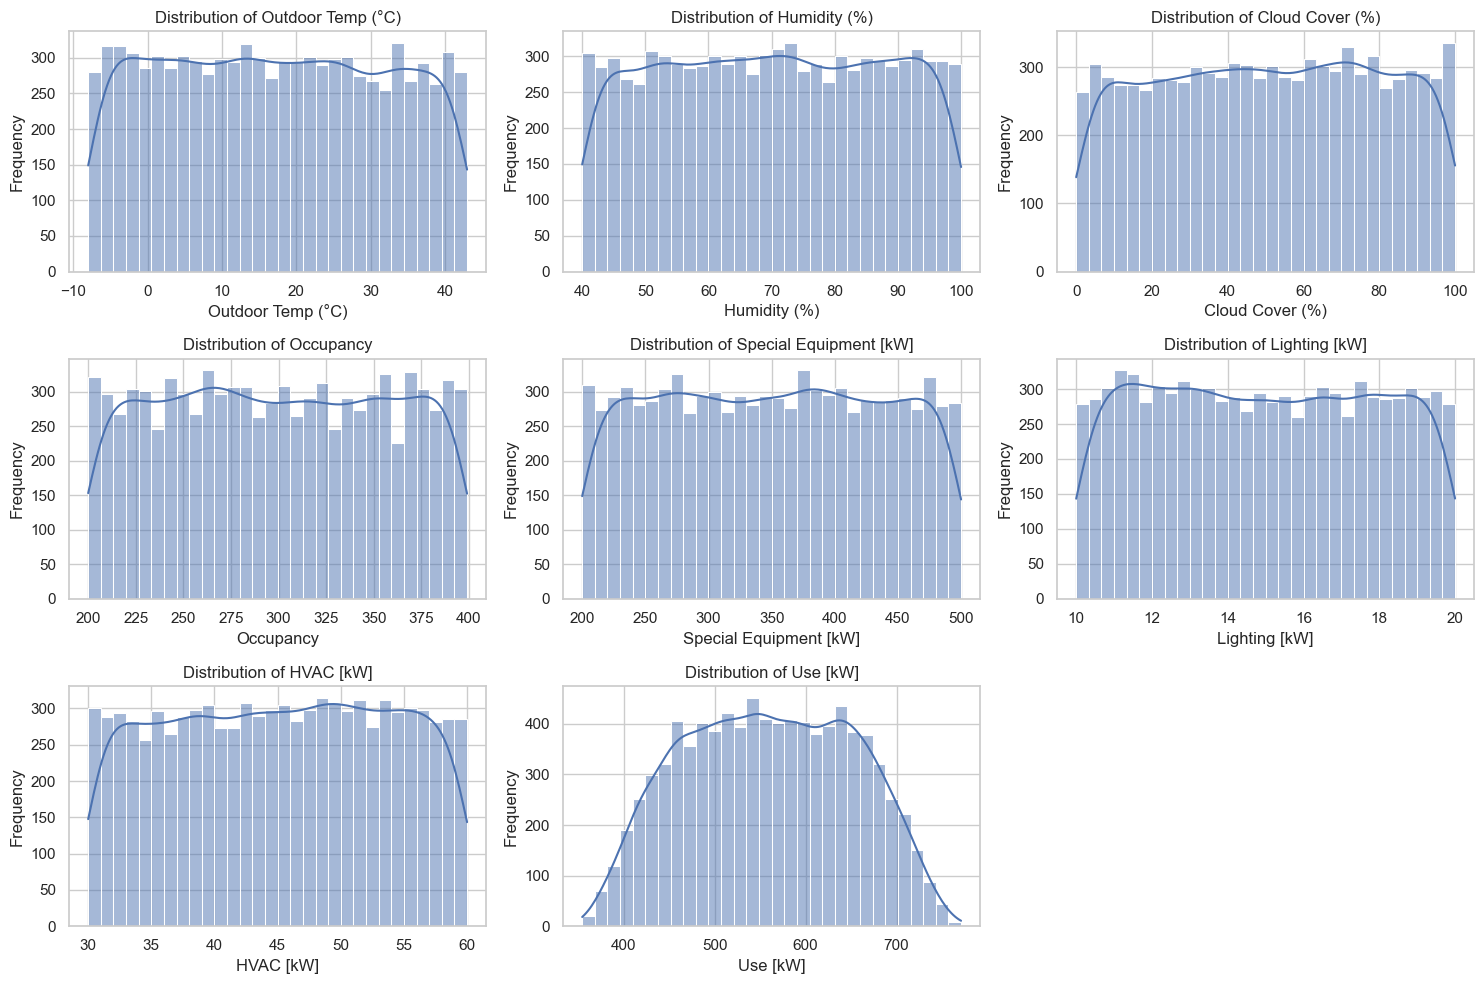

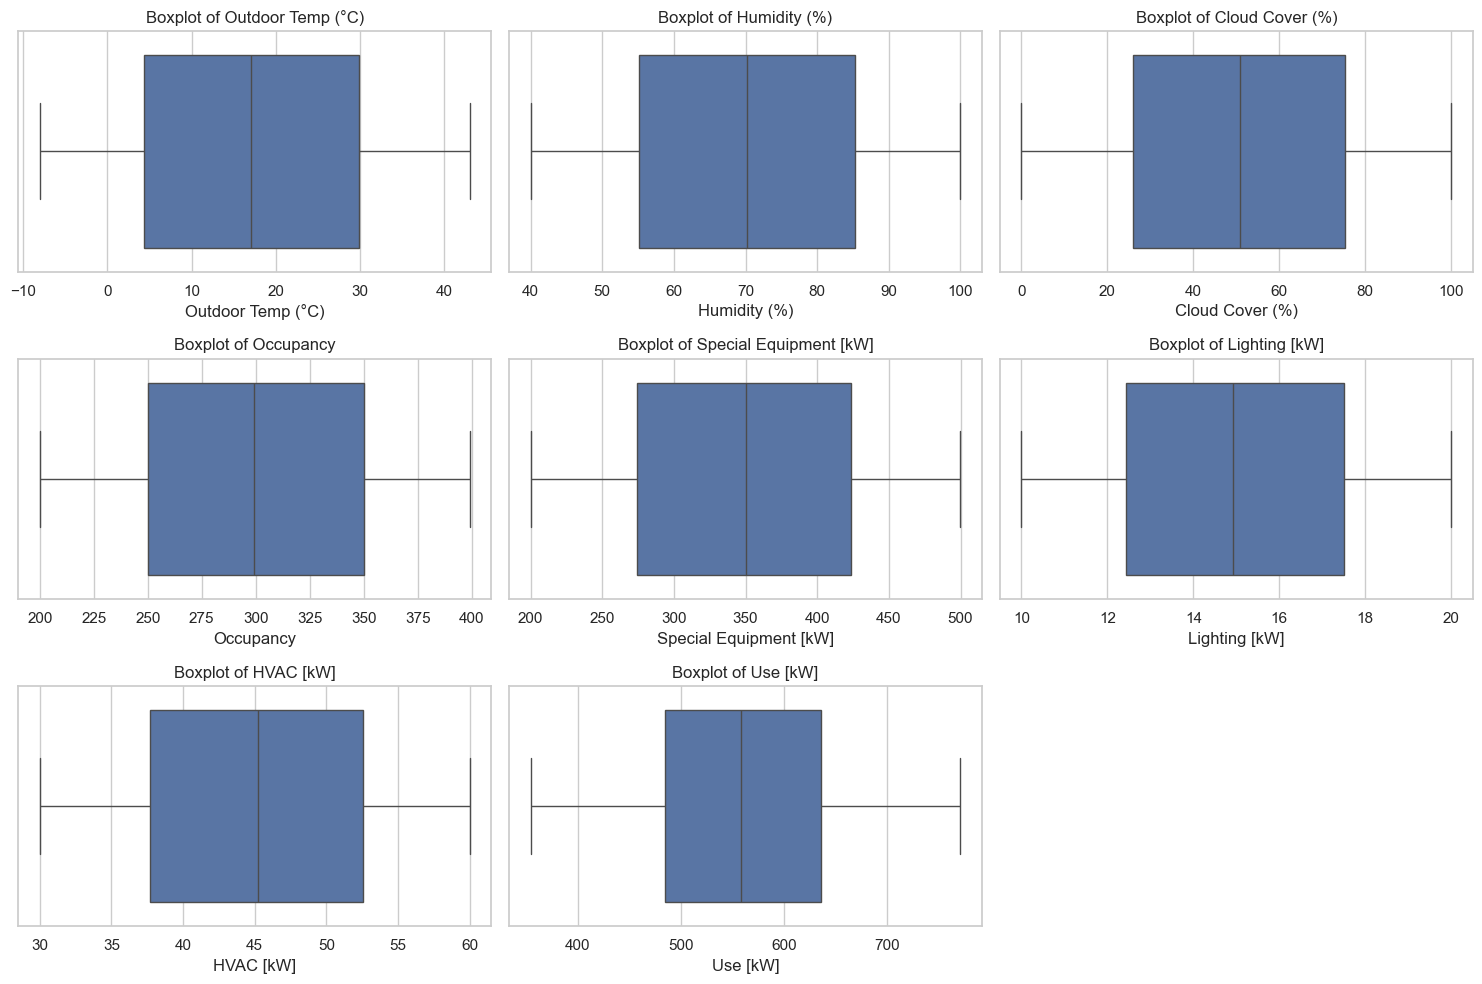

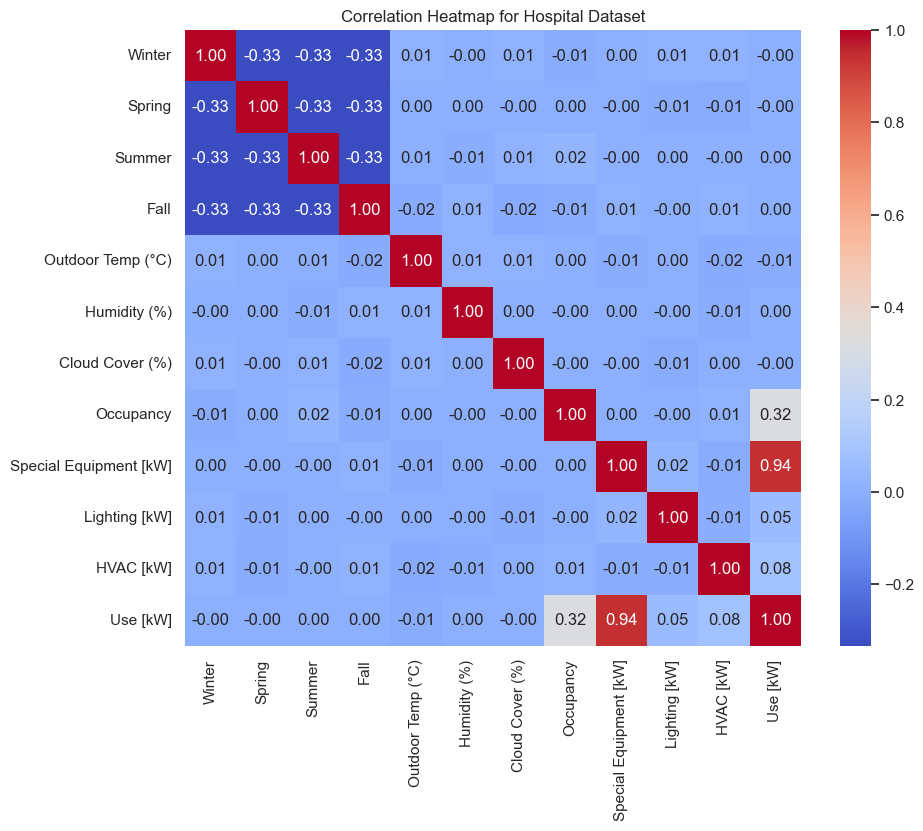


EDA for House1 Dataset
Basic Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Time                    8760 non-null   datetime64[ns]
 1   Winter                  8760 non-null   int64         
 2   Spring                  8760 non-null   int64         
 3   Summer                  8760 non-null   int64         
 4   Fall                    8760 non-null   int64         
 5   Outdoor Temp (°C)       8760 non-null   float64       
 6   Humidity (%)            8760 non-null   float64       
 7   Cloud Cover (%)         8760 non-null   float64       
 8   Occupancy               8760 non-null   int64         
 9   Special Equipment [kW]  8760 non-null   float64       
 10  Lighting [kW]           8760 non-null   float64       
 11  HVAC [kW]               8760 non-null   float64       
 12  Use [

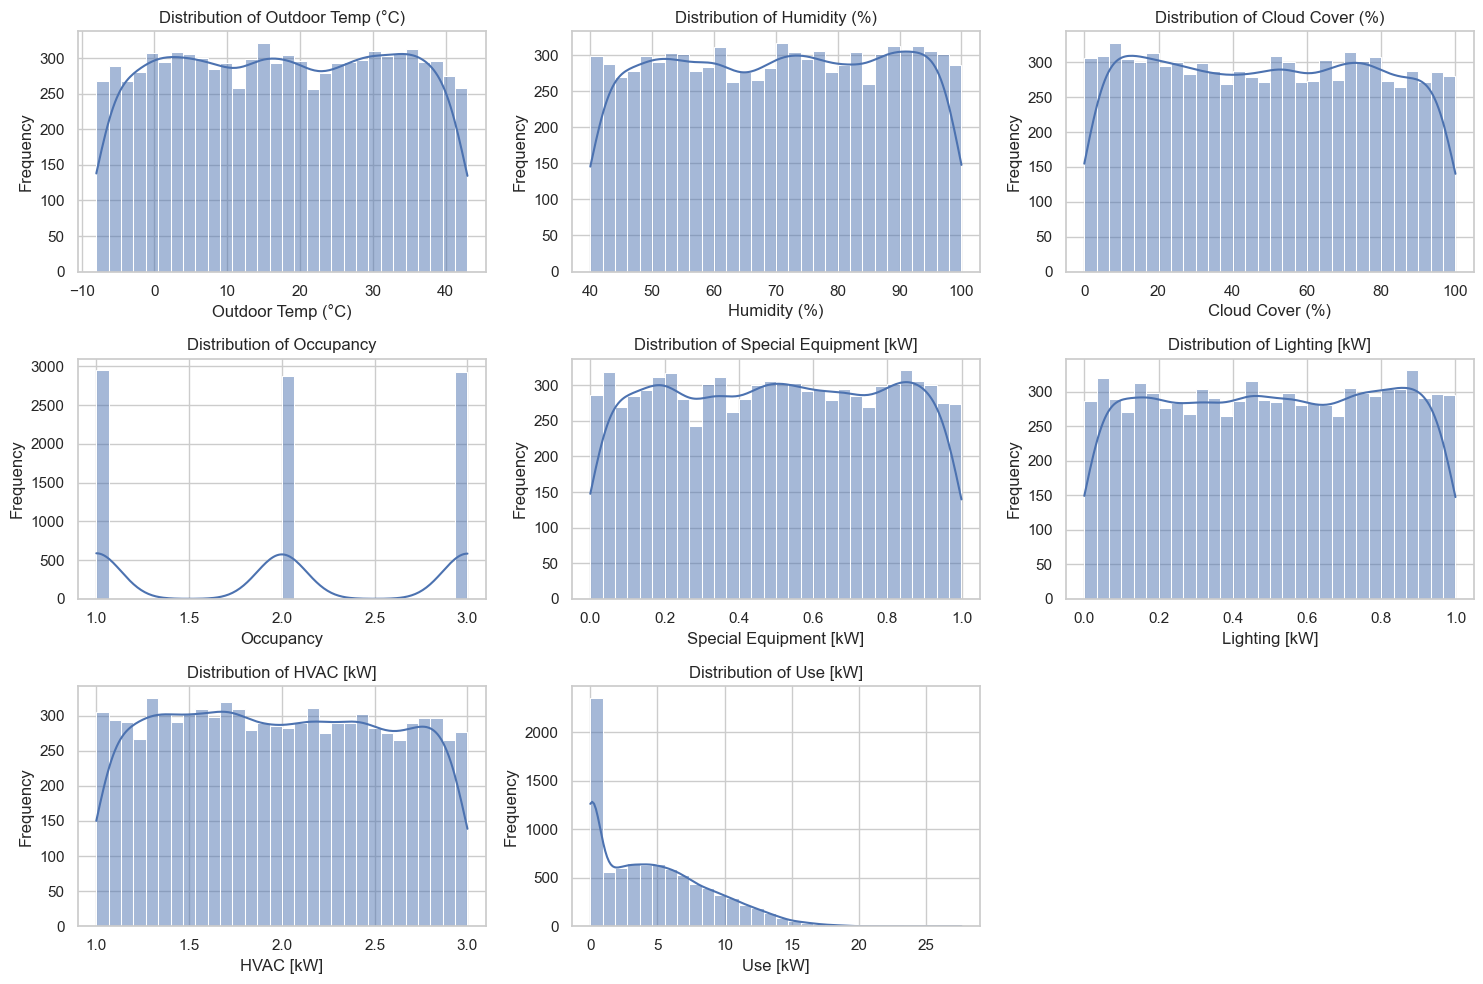

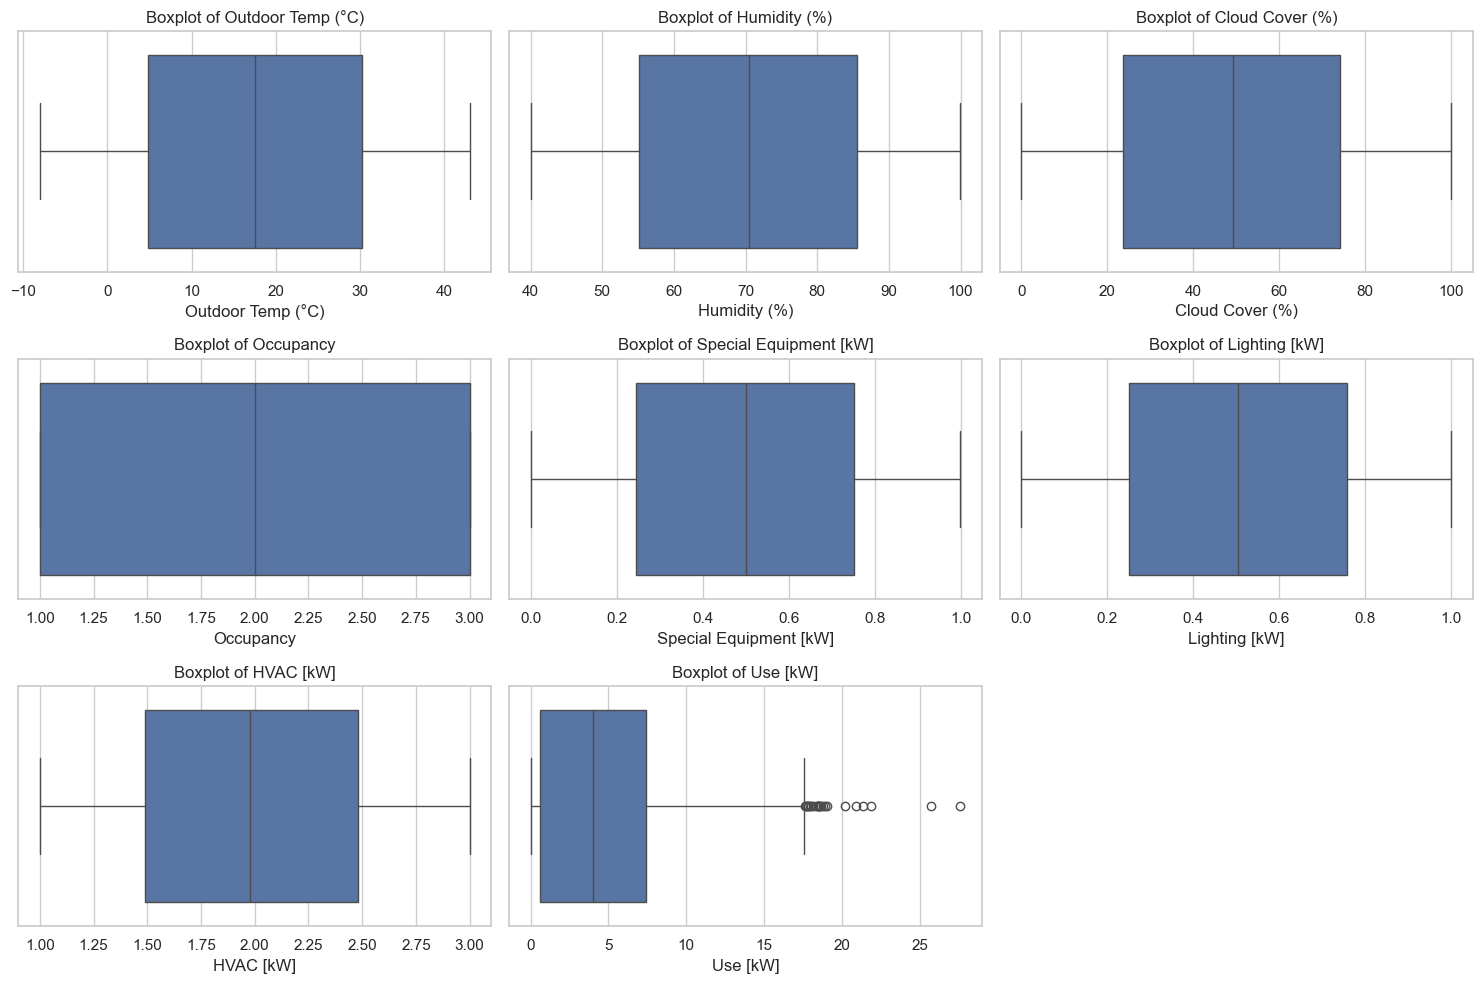

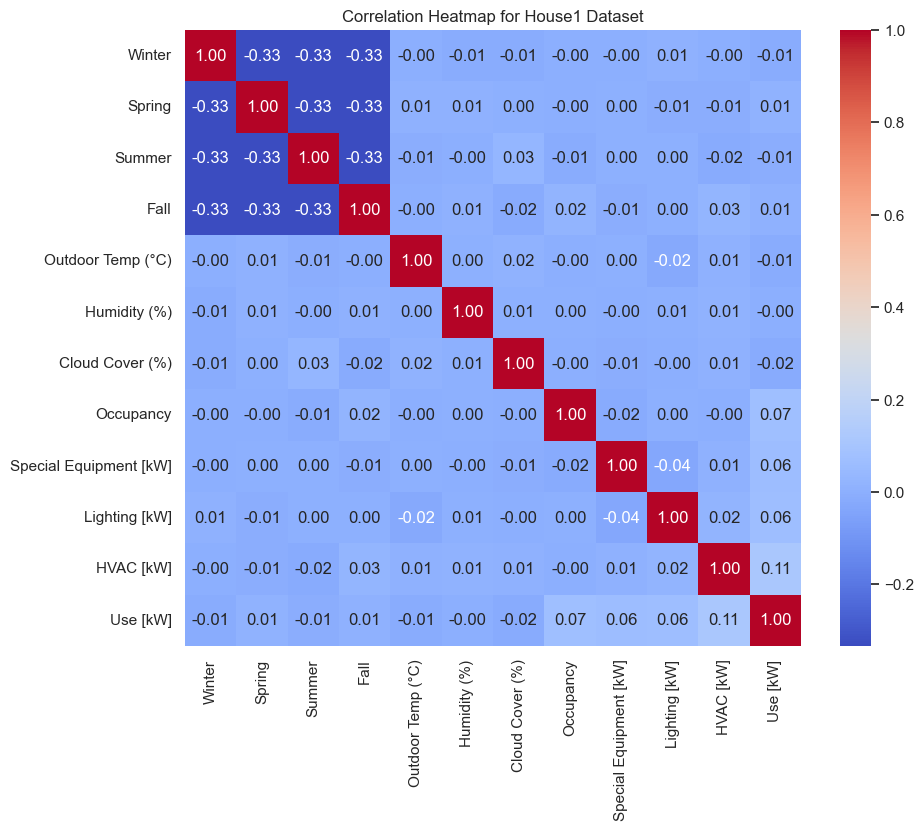


EDA for House2 Dataset
Basic Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Time                    8760 non-null   datetime64[ns]
 1   Winter                  8760 non-null   int64         
 2   Spring                  8760 non-null   int64         
 3   Summer                  8760 non-null   int64         
 4   Fall                    8760 non-null   int64         
 5   Outdoor Temp (°C)       8760 non-null   float64       
 6   Humidity (%)            8760 non-null   float64       
 7   Cloud Cover (%)         8760 non-null   float64       
 8   Occupancy               8760 non-null   int64         
 9   Special Equipment [kW]  8760 non-null   float64       
 10  Lighting [kW]           8760 non-null   float64       
 11  HVAC [kW]               8760 non-null   float64       
 12  Use [

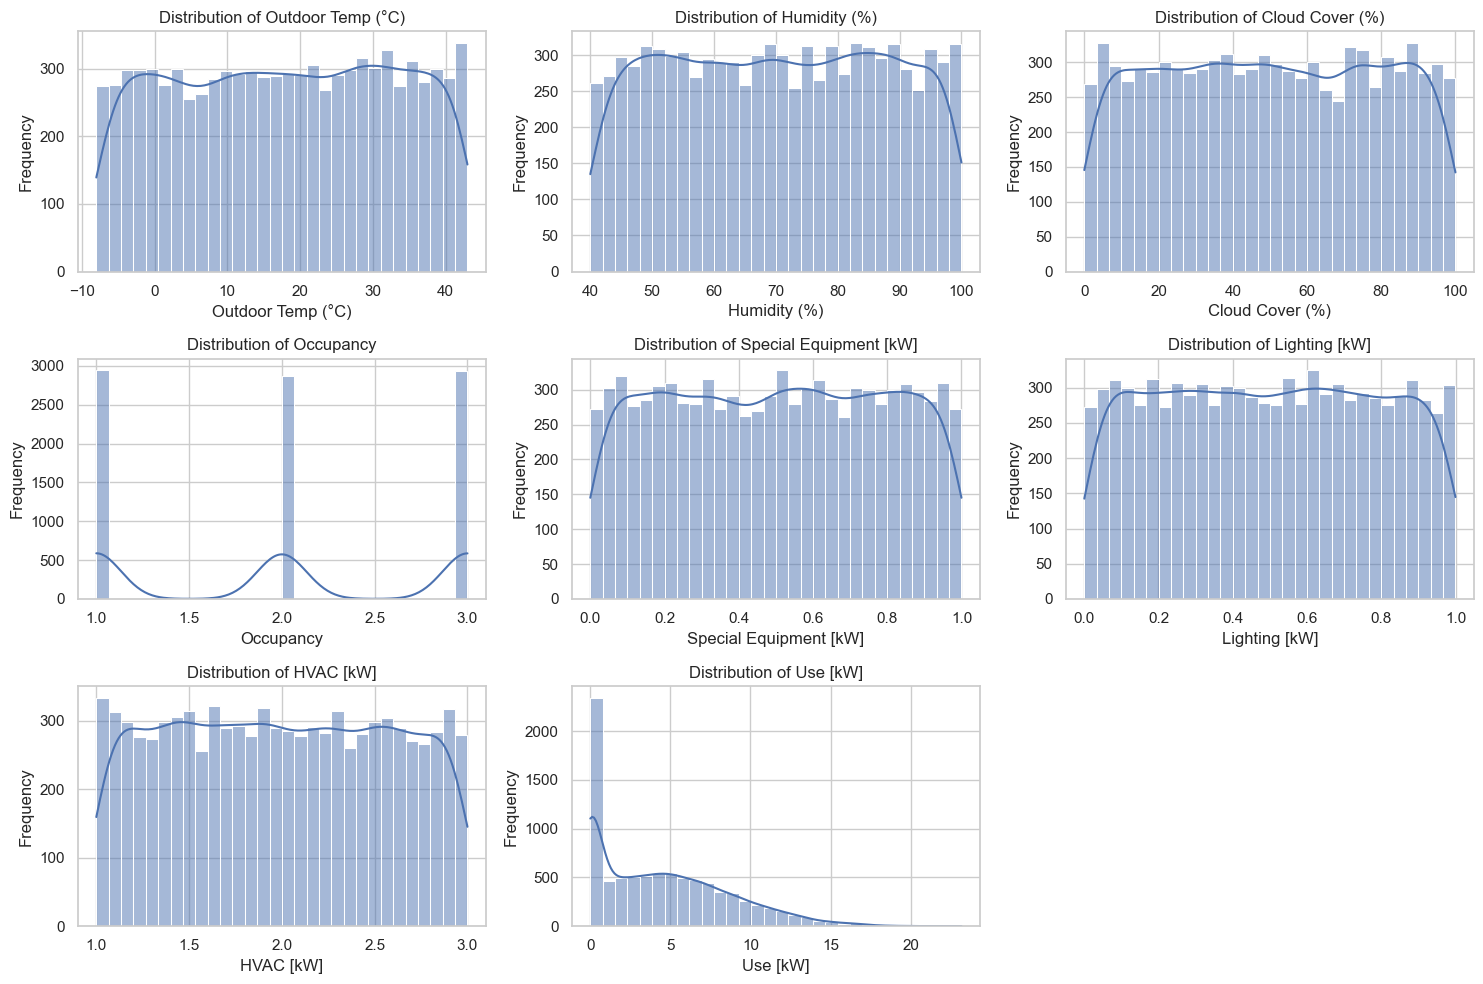

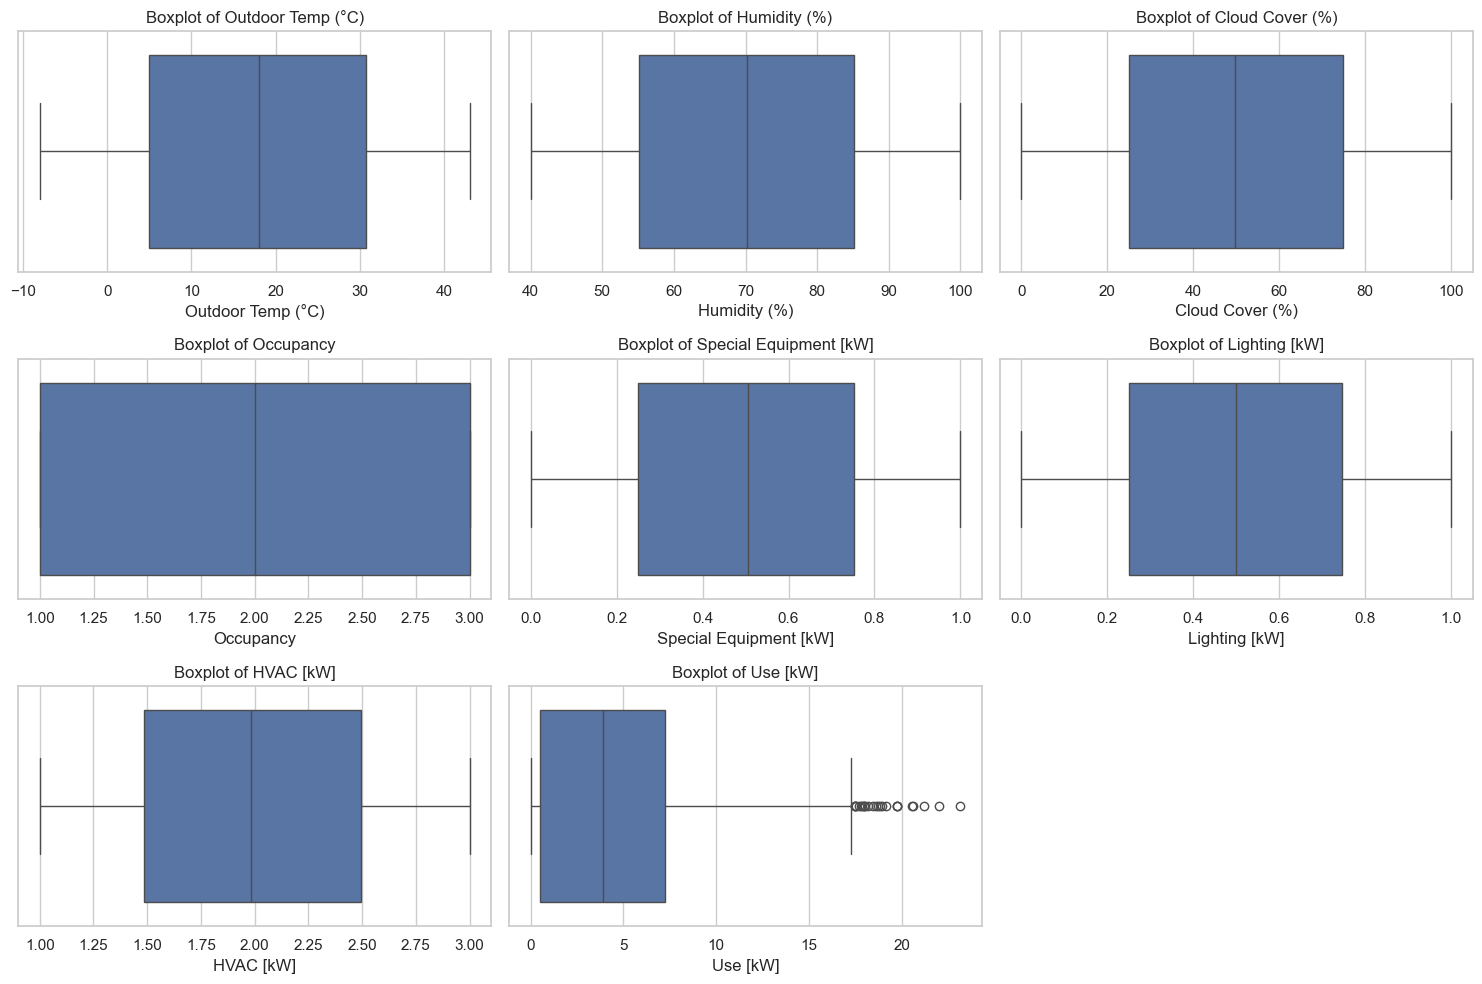

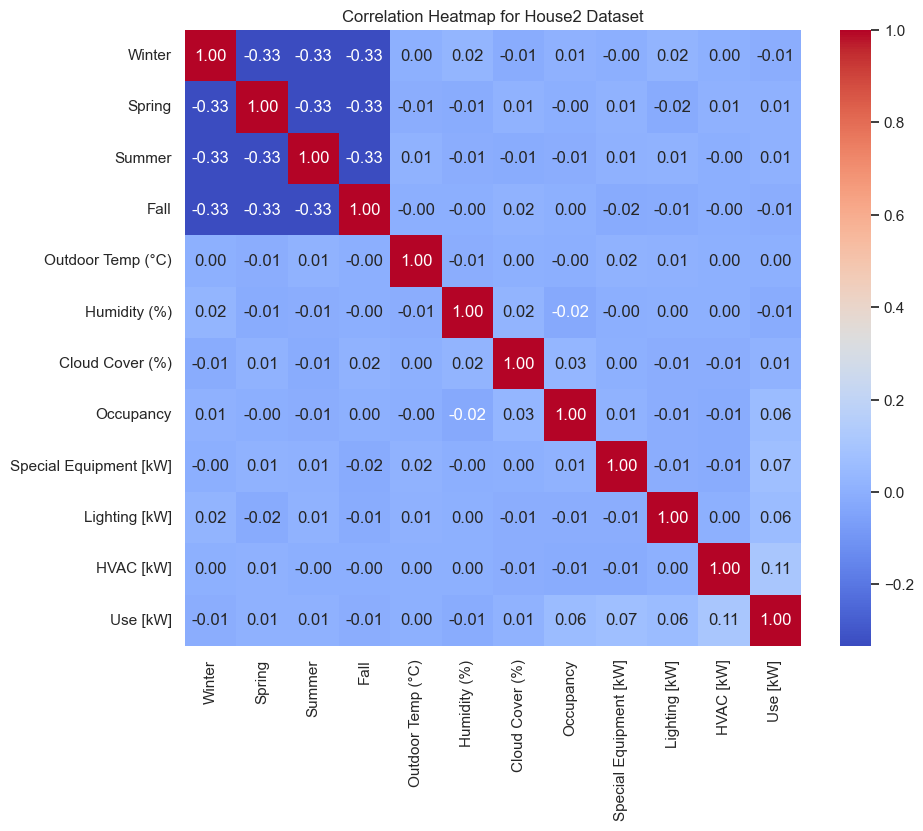


EDA for Industry Dataset
Basic Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Time                    8760 non-null   datetime64[ns]
 1   Winter                  8760 non-null   int64         
 2   Spring                  8760 non-null   int64         
 3   Summer                  8760 non-null   int64         
 4   Fall                    8760 non-null   int64         
 5   Outdoor Temp (°C)       8760 non-null   float64       
 6   Humidity (%)            8760 non-null   float64       
 7   Cloud Cover (%)         8760 non-null   float64       
 8   Occupancy               8760 non-null   int64         
 9   Special Equipment [kW]  8760 non-null   float64       
 10  Lighting [kW]           8760 non-null   float64       
 11  HVAC [kW]               8760 non-null   float64       
 12  Use

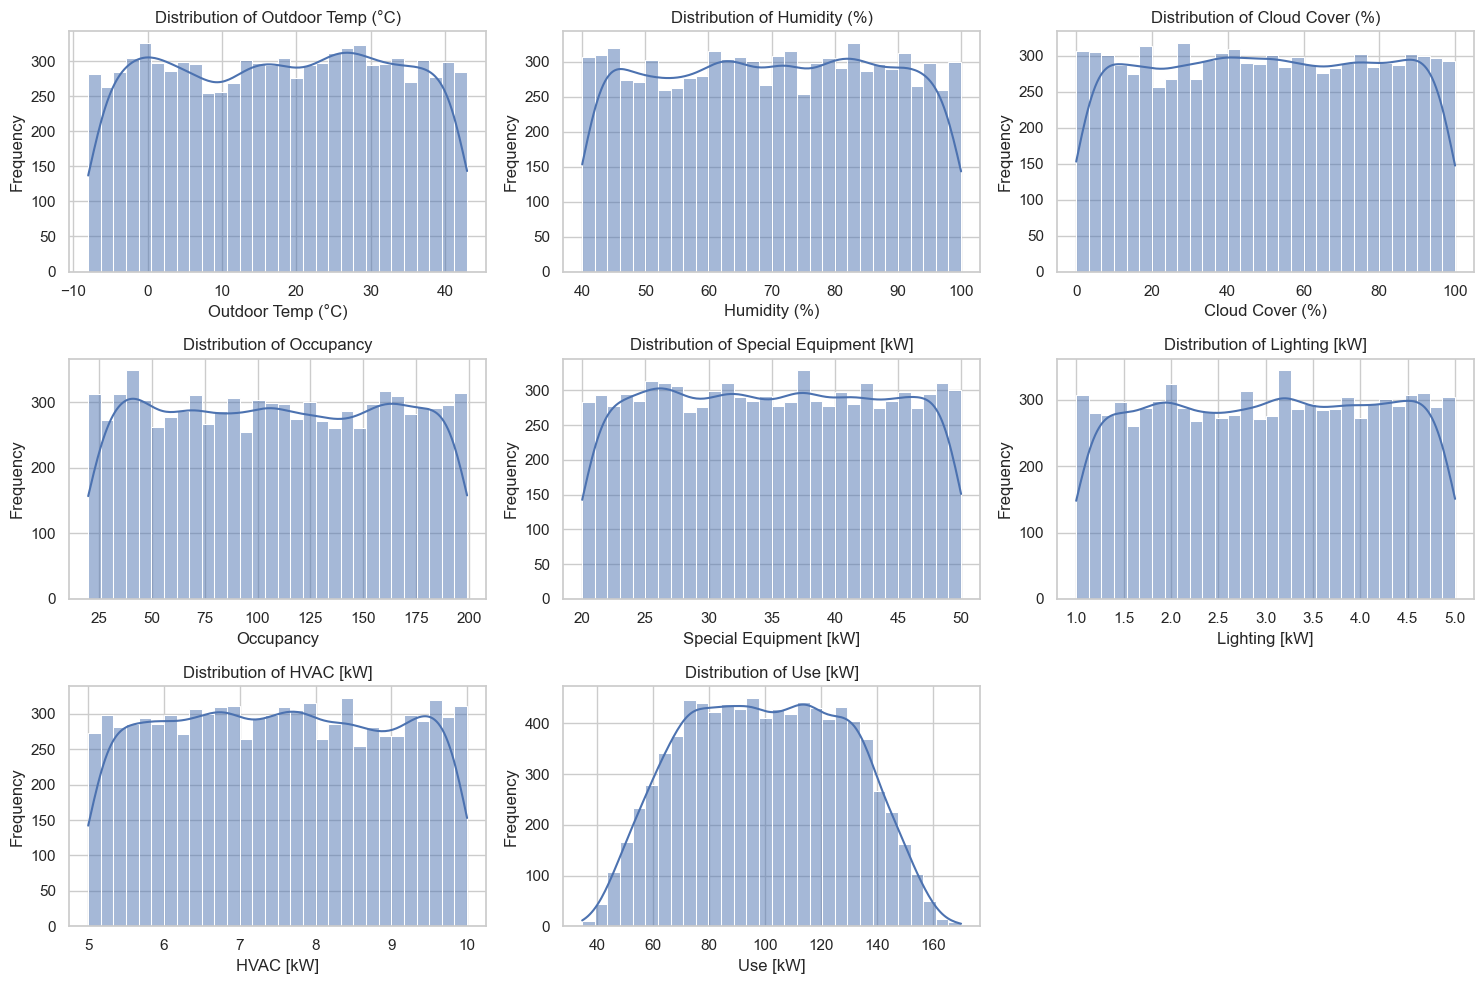

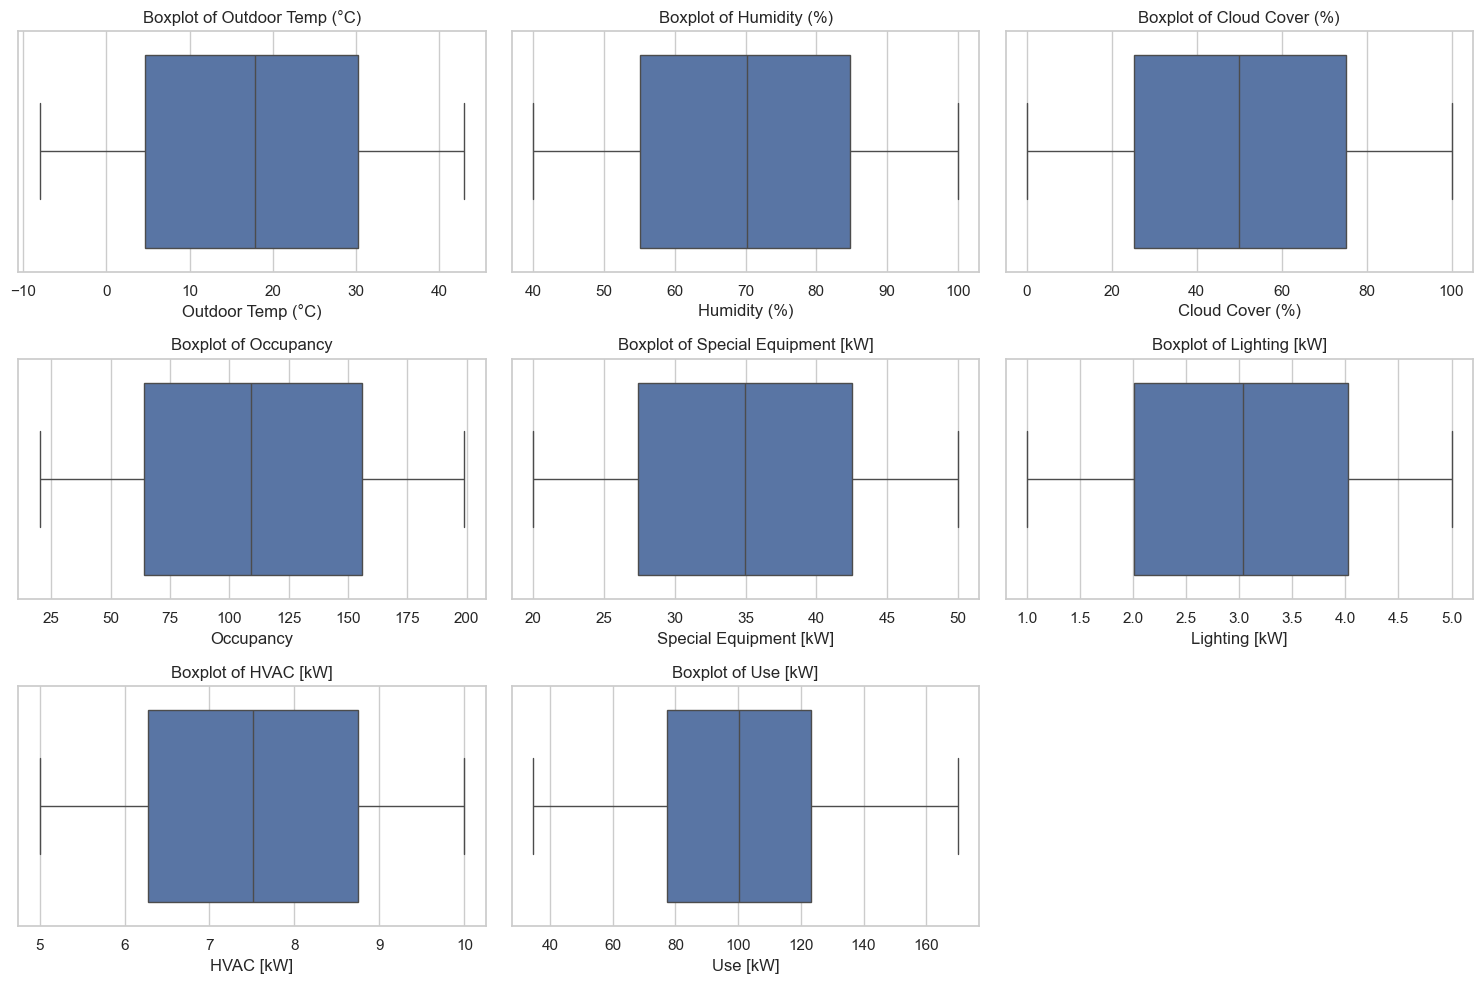

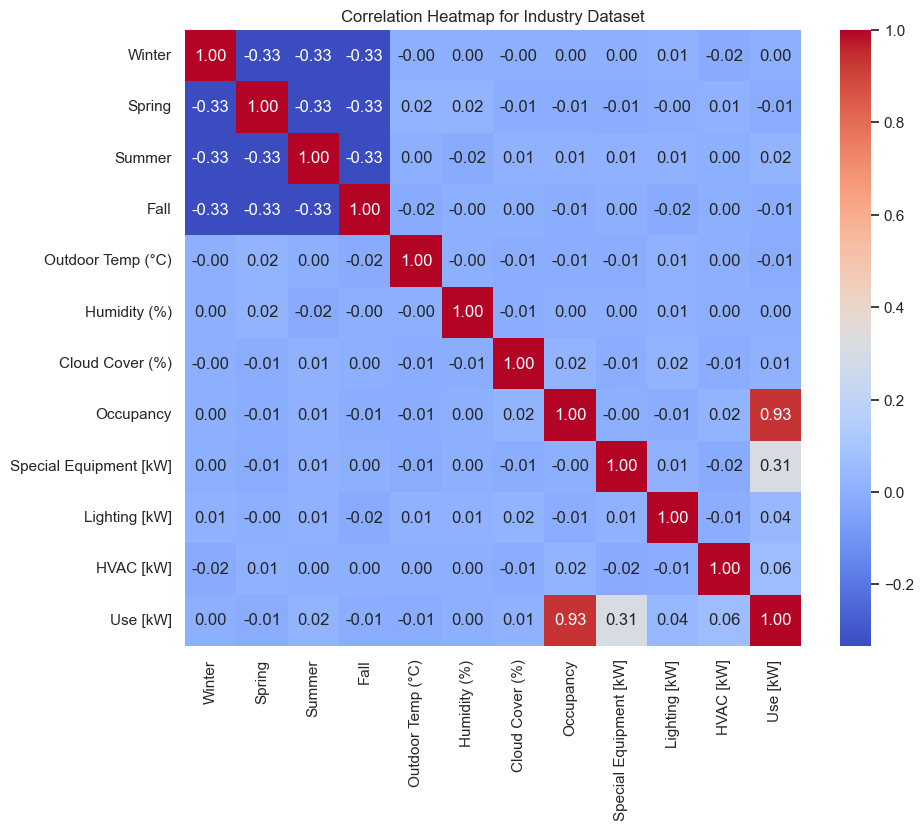


EDA for School Dataset
Basic Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Time                    8760 non-null   datetime64[ns]
 1   Winter                  8760 non-null   int64         
 2   Spring                  8760 non-null   int64         
 3   Summer                  8760 non-null   int64         
 4   Fall                    8760 non-null   int64         
 5   Outdoor Temp (°C)       8760 non-null   float64       
 6   Humidity (%)            8760 non-null   float64       
 7   Cloud Cover (%)         8760 non-null   float64       
 8   Occupancy               8760 non-null   int64         
 9   Special Equipment [kW]  8760 non-null   float64       
 10  Lighting [kW]           8760 non-null   float64       
 11  HVAC [kW]               8760 non-null   float64       
 12  Use [

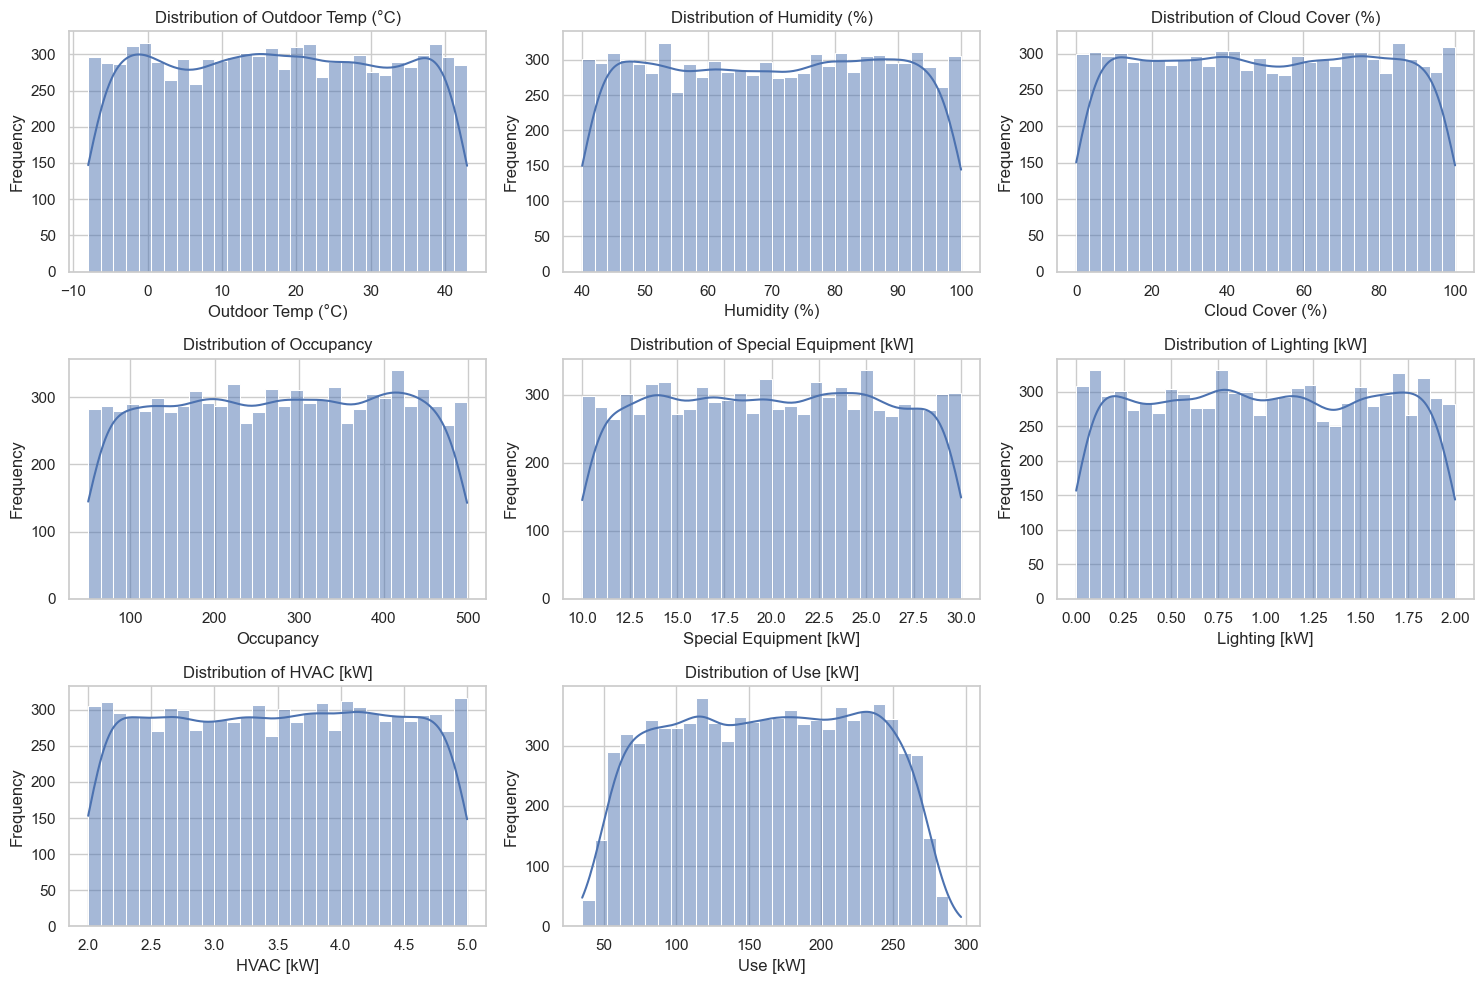

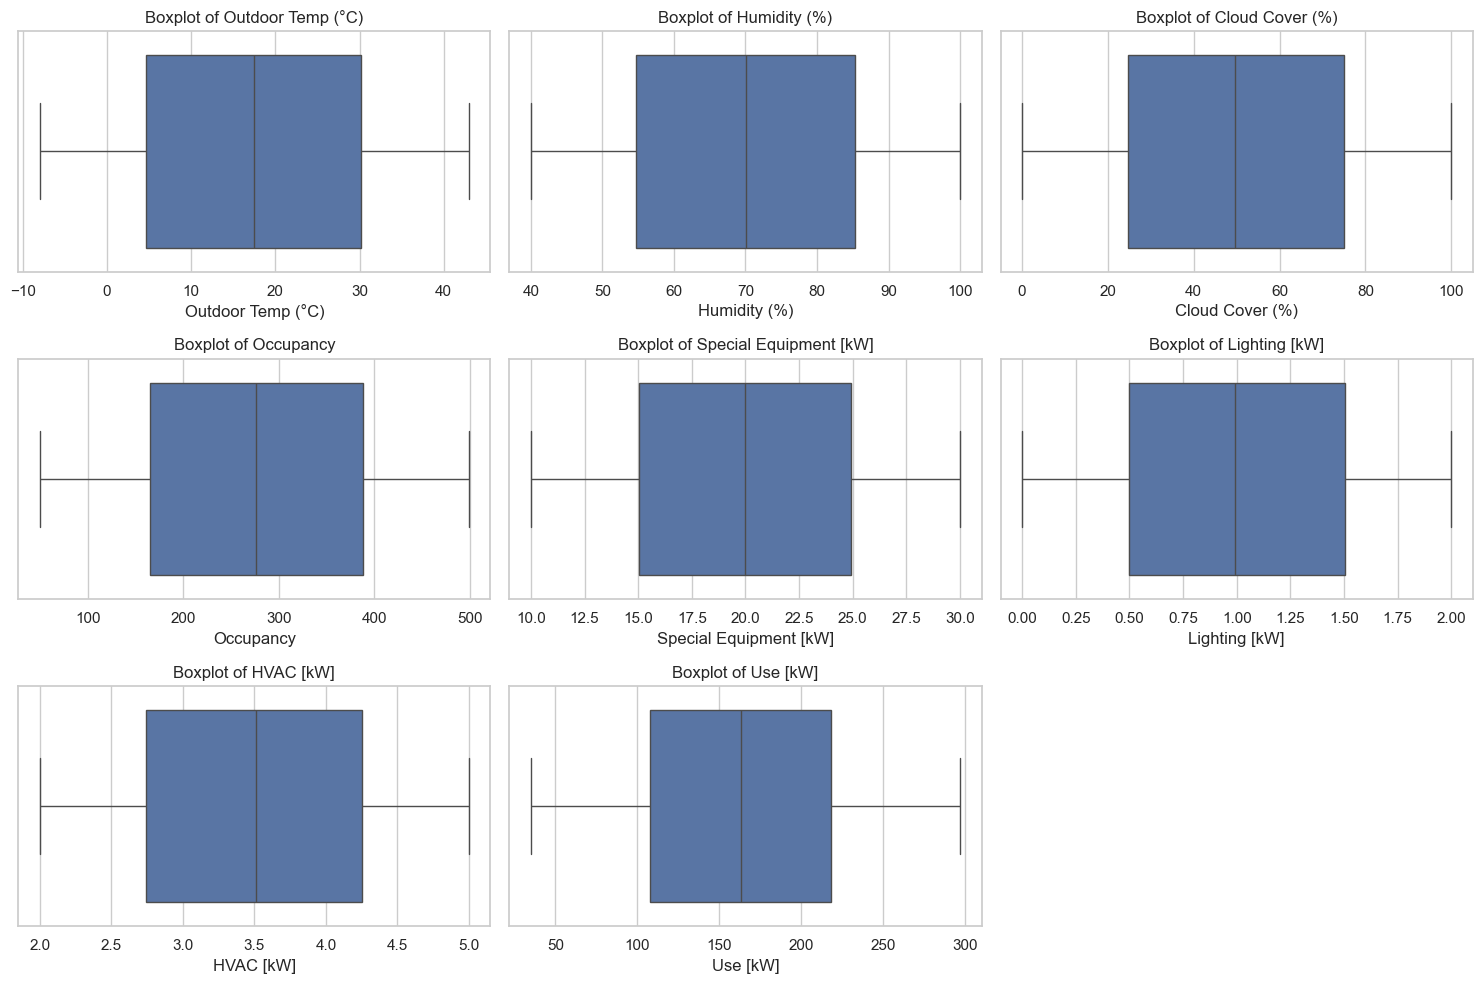

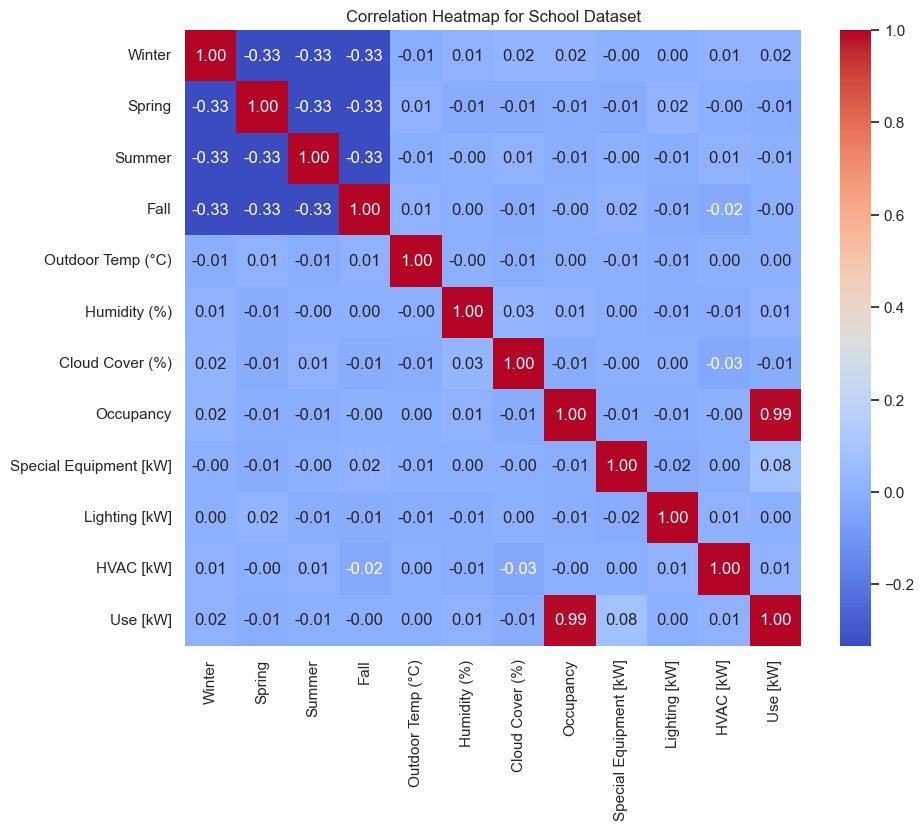


EDA for Office Dataset
Basic Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Time                    8760 non-null   datetime64[ns]
 1   Winter                  8760 non-null   int64         
 2   Spring                  8760 non-null   int64         
 3   Summer                  8760 non-null   int64         
 4   Fall                    8760 non-null   int64         
 5   Outdoor Temp (°C)       8760 non-null   float64       
 6   Humidity (%)            8760 non-null   float64       
 7   Cloud Cover (%)         8760 non-null   float64       
 8   Occupancy               8760 non-null   int64         
 9   Special Equipment [kW]  8760 non-null   float64       
 10  Lighting [kW]           8760 non-null   float64       
 11  HVAC [kW]               8760 non-null   float64       
 12  Use [

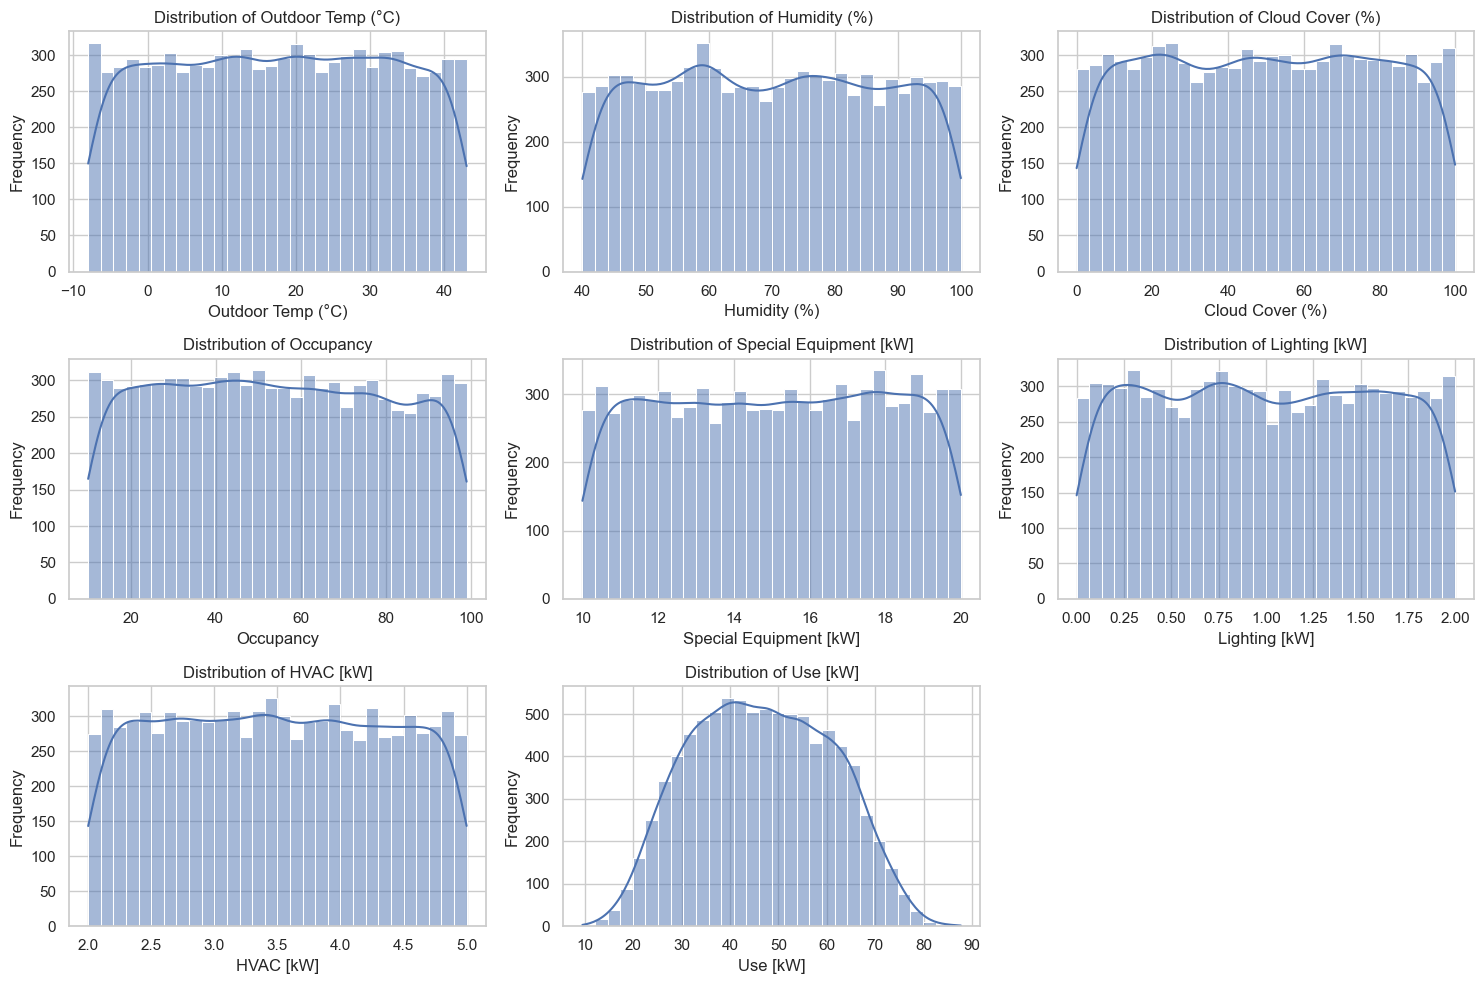

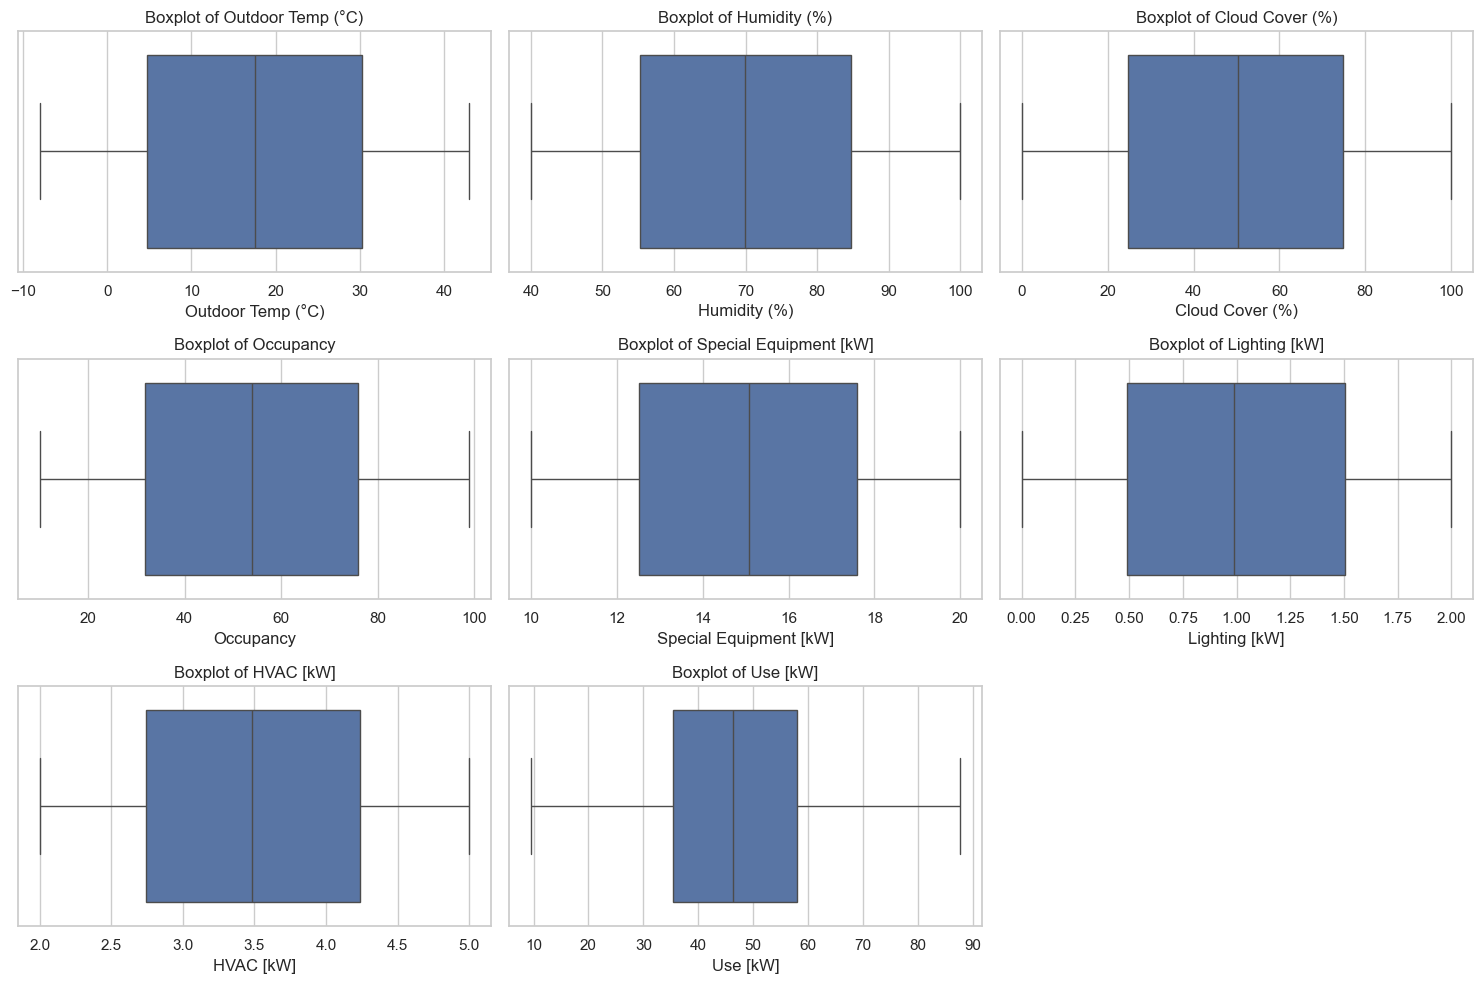

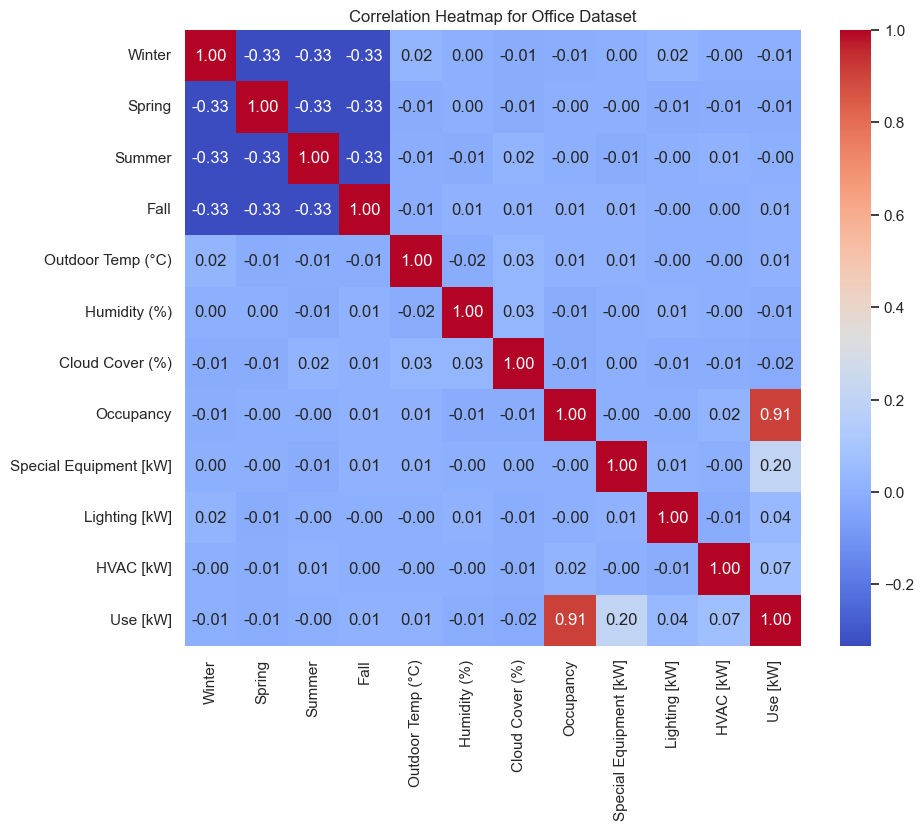

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set the style for seaborn
sns.set(style="whitegrid")

# List of building types
building_types = ['Hospital', 'House1', 'House2', 'Industry', 'School', 'Office']

# Function to perform EDA on each dataset
def perform_eda(building):
    # Load the dataset
    df = pd.read_csv(f'{building}_data.csv')

    # Convert 'Time' column to datetime format if present
    if 'Time' in df.columns:
        df['Time'] = pd.to_datetime(df['Time'])

    # Display basic information
    print(f"\nEDA for {building} Dataset")
    print("=" * 50)
    print("Basic Information:")
    print(df.info())
    
    # Display descriptive statistics
    print("\nDescriptive Statistics:")
    print(df.describe())
    
    # Check for missing values
    print("\nMissing Values:")
    print(df.isnull().sum())
    
    # Plot distributions of key features
    features_to_plot = ['Outdoor Temp (°C)', 'Humidity (%)', 'Cloud Cover (%)', 'Occupancy', 
                        'Special Equipment [kW]', 'Lighting [kW]', 'HVAC [kW]', 'Use [kW]']
    
    plt.figure(figsize=(15, 10))
    for i, feature in enumerate(features_to_plot):
        plt.subplot(3, 3, i + 1)
        sns.histplot(df[feature], bins=30, kde=True)
        plt.title(f'Distribution of {feature}')
        plt.xlabel(feature)
        plt.ylabel('Frequency')
    
    plt.tight_layout()
    plt.show()

    # Plot boxplots for each feature
    plt.figure(figsize=(15, 10))
    for i, feature in enumerate(features_to_plot):
        plt.subplot(3, 3, i + 1)
        sns.boxplot(x=df[feature])
        plt.title(f'Boxplot of {feature}')
        plt.xlabel(feature)

    plt.tight_layout()
    plt.show()
    
    # Plot correlation heatmap (exclude non-numeric columns)
    numeric_df = df.select_dtypes(include=['float64', 'int64'])
    
    plt.figure(figsize=(10, 8))
    correlation_matrix = numeric_df.corr()
    sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True)
    plt.title(f'Correlation Heatmap for {building} Dataset')
    plt.show()

# Perform EDA for each building dataset
for building in building_types:
    perform_eda(building)


In [19]:
import pandas as pd
import numpy as np
import random

# Set random seed for reproducibility
random.seed(42)
np.random.seed(42)

# Constants
hours_per_year = 8760
building_types = ['Hospital', 'House1', 'House2', 'Industry', 'School', 'Office']
seasons = ['Winter', 'Spring', 'Summer', 'Fall']
temperature_range = (-8, 43)  # Outdoor temperature range in °C
humidity_range = (40, 100)     # Humidity range in %
cloud_cover_range = (0, 100)   # Cloud cover range in %

occupancy_range = {
    'Hospital': (200, 400),
    'House1': (1, 4),
    'House2': (1, 4),
    'Industry': (20, 200),
    'School': (50, 500),
    'Office': (10, 100)
}

special_equipment_range = {
    'Hospital': (200, 500),
    'House1': (0, 1),
    'House2': (0, 1),
    'Industry': (20, 50),
    'School': (10, 30),
    'Office': (10, 20)
}

lighting_range = {
    'Hospital': (10, 20),
    'House1': (0, 1),
    'House2': (0, 1),
    'Industry': (1, 5),
    'School': (0, 2),
    'Office': (0, 2)
}

hvac_range = {
    'Hospital': (30, 60),
    'House1': (1, 3),
    'House2': (1, 3),
    'Industry': (5, 10),
    'School': (2, 5),
    'Office': (2, 5)
}

def add_temporal_features(df):
    df['Hour'] = df['Time'].dt.hour
    df['DayOfWeek'] = df['Time'].dt.dayofweek
    df['Month'] = df['Time'].dt.month
    df['IsWeekend'] = df['DayOfWeek'].isin([5, 6]).astype(int)
    df['IsHoliday'] = (df['Time'].dt.month == 12) & (df['Time'].dt.day == 25)  # Example holiday
    return df

def add_usage_patterns(df, building_type):
    # Business hours pattern (except for residential)
    if building_type not in ['House1', 'House2']:
        business_hours = (df['Hour'].between(9, 17)) & (~df['IsWeekend'])
        df['Occupancy'] = np.where(business_hours, 
                                 df['Occupancy'], 
                                 df['Occupancy'] * 0.2)  # Lower occupancy outside business hours
    
    # Temperature-dependent HVAC usage
    df['HVAC [kW]'] = df['HVAC [kW]'] * (
        1 + 0.3 * np.sin(np.pi * df['Hour'] / 12) +  # Daily cycle
        0.5 * (df['Outdoor Temp (°C)'] - 20).abs() / 20  # Temperature impact
    )
    
    return df

def add_feature_correlations(df):
    # Lighting correlates with cloud cover and time of day
    df['Lighting [kW]'] = df['Lighting [kW]'] * (
        1 - 0.3 * df['Cloud Cover (%)'] / 100 +  # More lighting on cloudy days
        0.4 * np.sin(np.pi * df['Hour'] / 12)    # Daily cycle
    )
    
    # Special equipment correlates with occupancy
    df['Special Equipment [kW]'] = df['Special Equipment [kW]'] * (
        0.7 + 0.3 * df['Occupancy'] / df['Occupancy'].max()
    )
    
    return df

def generate_building_data(building_type):
    data = {
        'Time': pd.date_range(start='2023-01-01', periods=hours_per_year, freq='H'),
        'Season': [seasons[(i // (hours_per_year // 4)) % 4] for i in range(hours_per_year)],
        'Winter': [1 if (i // (hours_per_year // 4)) % 4 == 0 else 0 for i in range(hours_per_year)],
        'Spring': [1 if (i // (hours_per_year // 4)) % 4 == 1 else 0 for i in range(hours_per_year)],
        'Summer': [1 if (i // (hours_per_year // 4)) % 4 == 2 else 0 for i in range(hours_per_year)],
        'Fall': [1 if (i // (hours_per_year // 4)) % 4 == 3 else 0 for i in range(hours_per_year)],
        'Outdoor Temp (°C)': np.random.uniform(temperature_range[0], temperature_range[1], hours_per_year),
        'Humidity (%)': np.random.uniform(humidity_range[0], humidity_range[1], hours_per_year),
        'Cloud Cover (%)': np.random.uniform(cloud_cover_range[0], cloud_cover_range[1], hours_per_year),
        'Occupancy': np.random.randint(occupancy_range[building_type][0], occupancy_range[building_type][1], hours_per_year),
        'Special Equipment [kW]': np.random.uniform(special_equipment_range[building_type][0], special_equipment_range[building_type][1], hours_per_year),
        'Lighting [kW]': np.random.uniform(lighting_range[building_type][0], lighting_range[building_type][1], hours_per_year),
        'HVAC [kW]': np.random.uniform(hvac_range[building_type][0], hvac_range[building_type][1], hours_per_year),
    }
    
    df = pd.DataFrame(data)
    
    # Add new features and patterns
    df = add_temporal_features(df)
    df = add_usage_patterns(df, building_type)
    df = add_feature_correlations(df)
    
    # Calculate total use with more realistic relationships
    base_load = df['Special Equipment [kW]'] * 0.8  # Base load
    variable_load = (
        df['Lighting [kW]'] + 
        df['HVAC [kW]'] * (1 + 0.2 * df['Outdoor Temp (°C)'].clip(0, 30) / 30) +
        0.2 * df['Occupancy'] / df['Occupancy'].max()
    )
    
    df['Use [kW]'] = (base_load + variable_load) * (
        1 + np.random.normal(0, 0.05, len(df))  # 5% random variation
    )
    
    # One-hot encode the season variable
    df = pd.get_dummies(df, columns=['Season'], drop_first=True)
    return df

# Create an empty list to hold dataframes for each building
building_dfs = []

# Generate data for each building type
for building in building_types:
    building_df = generate_building_data(building)
    building_dfs.append(building_df)

# Save each dataframe to a separate CSV file
for building, df in zip(building_types, building_dfs):
    df.to_csv(f'{building}_data.csv', index=False)

print("Datasets generated and saved successfully.")

Datasets generated and saved successfully.


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Load your datasets (replace with actual file paths)
house1_data = pd.read_csv("House1_data.csv")
house2_data = pd.read_csv("House2_data.csv")
hospital_data = pd.read_csv("Hospital_data.csv")
industry_data = pd.read_csv("Industry_data.csv")
office_data = pd.read_csv("Office_data.csv")
school_data = pd.read_csv("School_data.csv")

# Combine datasets and add a 'Building Type' column for analysis
house1_data['Building Type'] = 'House1'
house2_data['Building Type'] = 'House2'
hospital_data['Building Type'] = 'Hospital'
industry_data['Building Type'] = 'Industry'
school_data['Building Type'] = 'School'
office_data['Building Type'] = 'office'

combined_data = pd.concat([house1_data, house2_data, hospital_data, industry_data, school_data, office_data], ignore_index=True)

# Features and Target
features = ['Time', 'Winter', 'Spring', 'Summer', 'Fall', 
            'Outdoor Temp (°C)', 'Humidity (%)', 'Cloud Cover (%)', 
            'Occupancy', 'Special Equipment [kW]', 'Lighting [kW]', 'HVAC [kW]', 'Hour', 'DayOfWeek', 'Month', 'IsWeekend', 'IsHoliday', 'Use [kW]']
target = 'Use [kW]'


C:\Users\haide\AppData\Local\Temp\ipykernel_16092\1629392646.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Building Type')


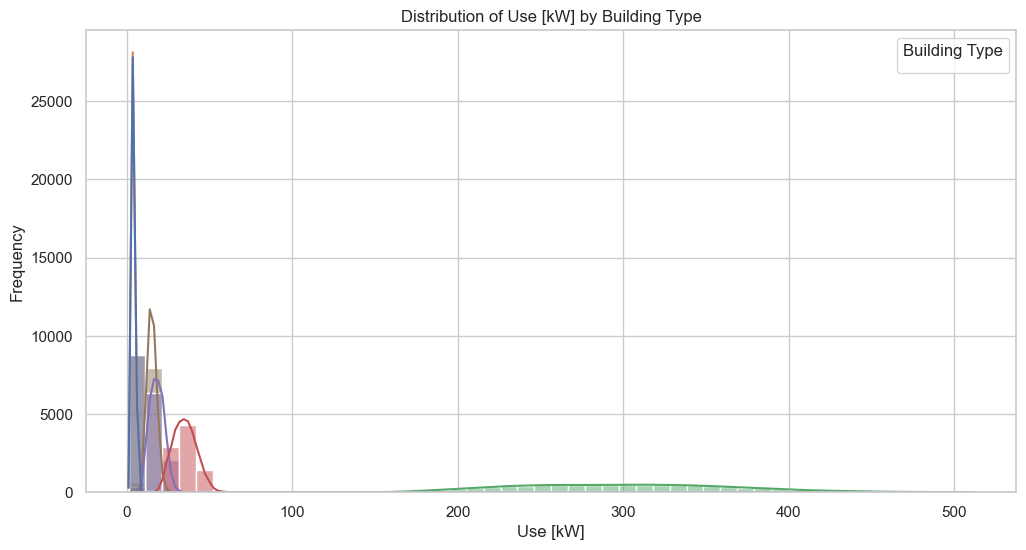

                count        mean        std         min         25%  \
Building Type                                                          
Hospital       8760.0  300.307011  64.204975  154.121037  250.487448   
House1         8760.0    3.827406   1.207894    1.105942    2.908415   
House2         8760.0    3.824699   1.185894    1.110071    2.925001   
Industry       8760.0   35.077091   7.002917   17.005653   29.917093   
School         8760.0   18.299311   4.275751    7.242450   15.046769   
office         8760.0   15.248019   2.836381    7.825442   13.241098   

                      50%         75%         max  
Building Type                                      
Hospital       298.362725  345.660759  511.821407  
House1           3.698433    4.608530    8.207110  
House2           3.694151    4.614100    8.100301  
Industry        34.868481   39.823449   62.565581  
School          18.136377   21.344777   34.828614  
office          15.093003   17.128972   27.035161  


In [10]:
# Plot histograms for each building type
plt.figure(figsize=(12, 6))
sns.histplot(data=combined_data, x=target, hue='Building Type', kde=True, bins=50)
plt.title('Distribution of Use [kW] by Building Type')
plt.xlabel('Use [kW]')
plt.ylabel('Frequency')
plt.legend(title='Building Type')
plt.show()

# Statistical summary
print(combined_data.groupby('Building Type')[target].describe())


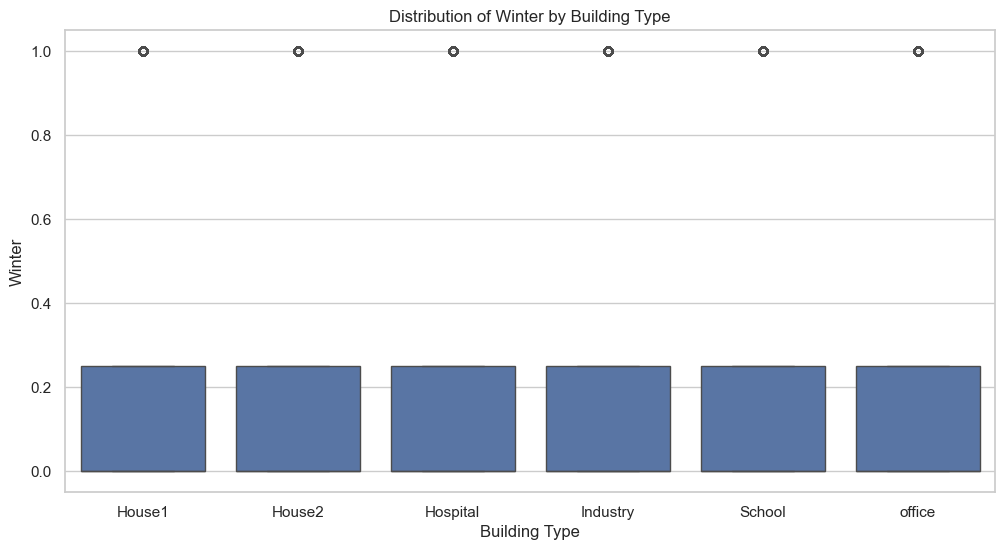

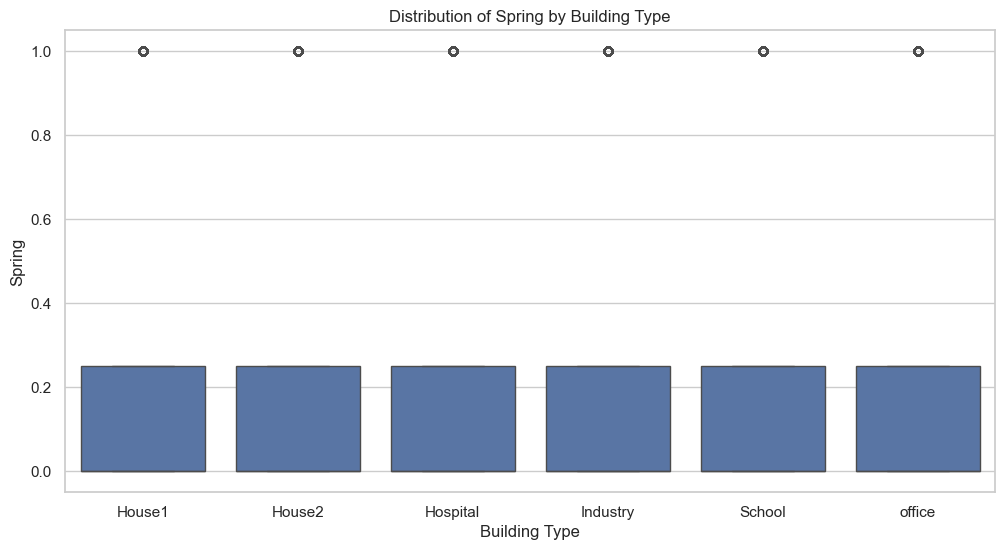

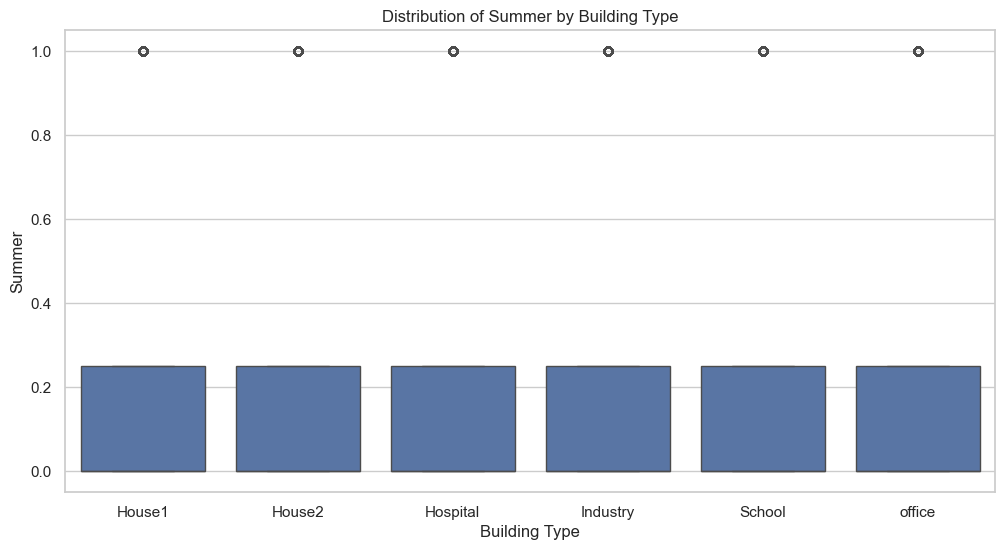

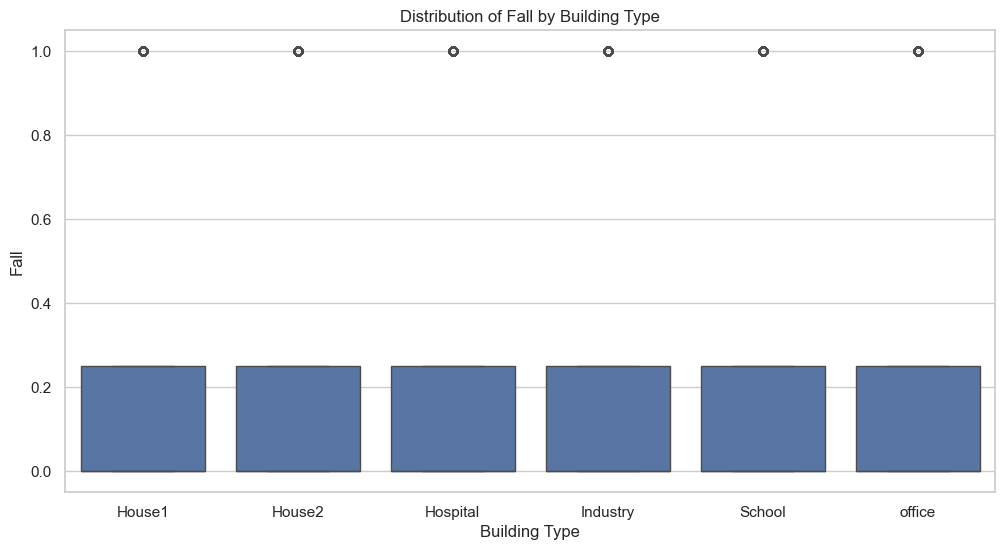

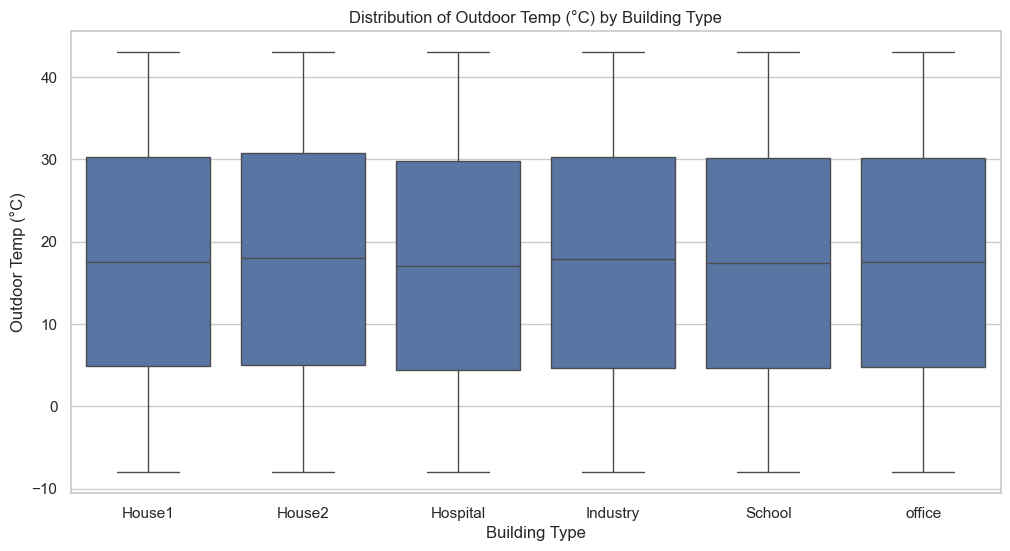

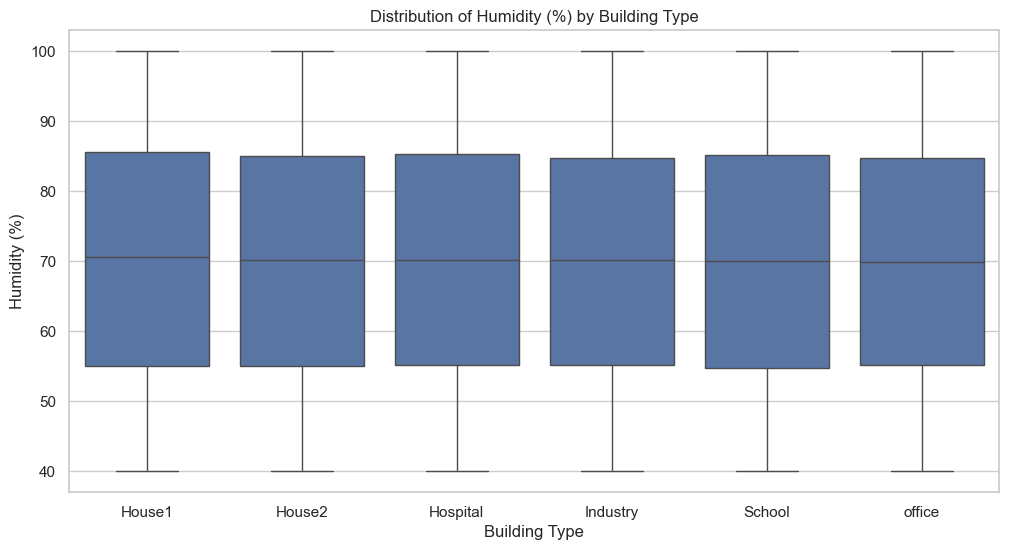

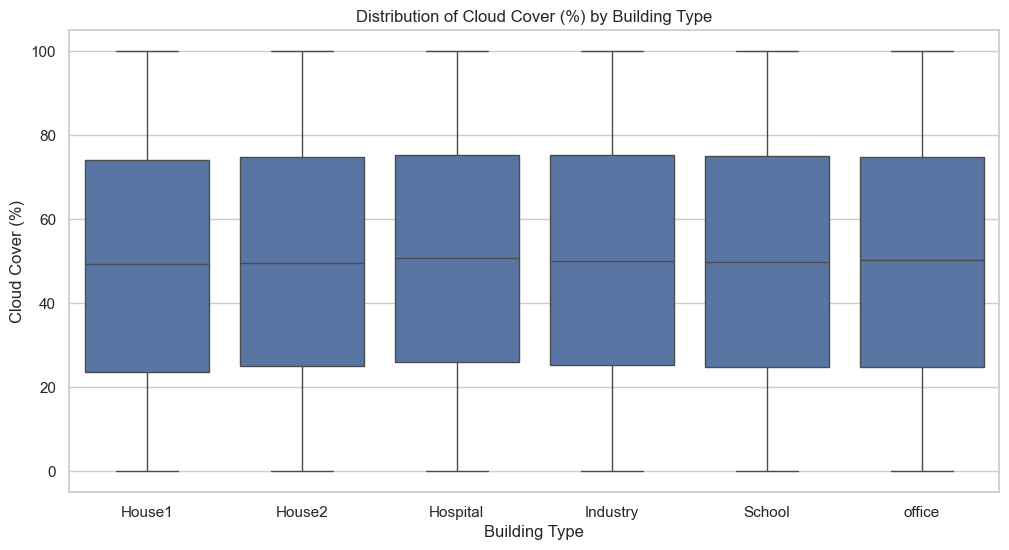

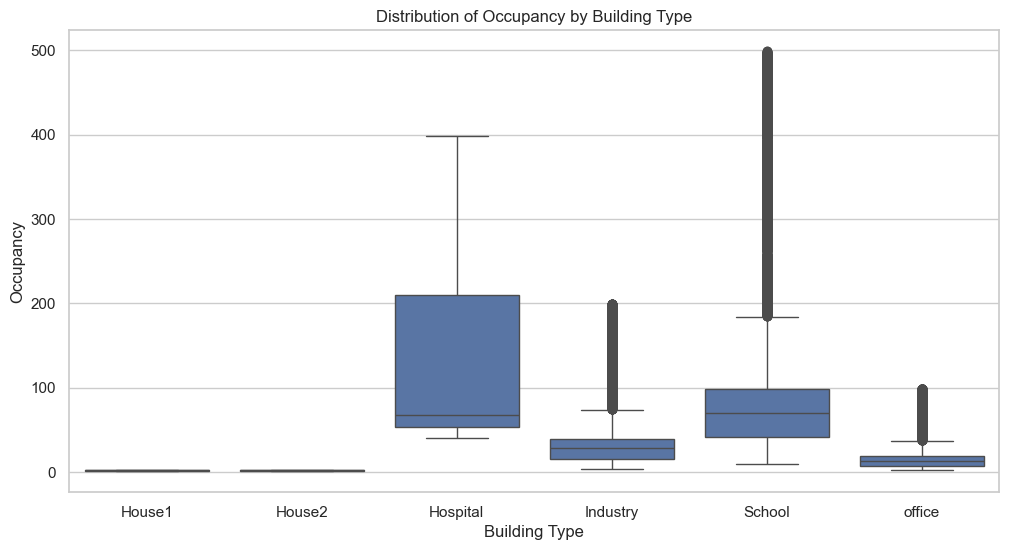

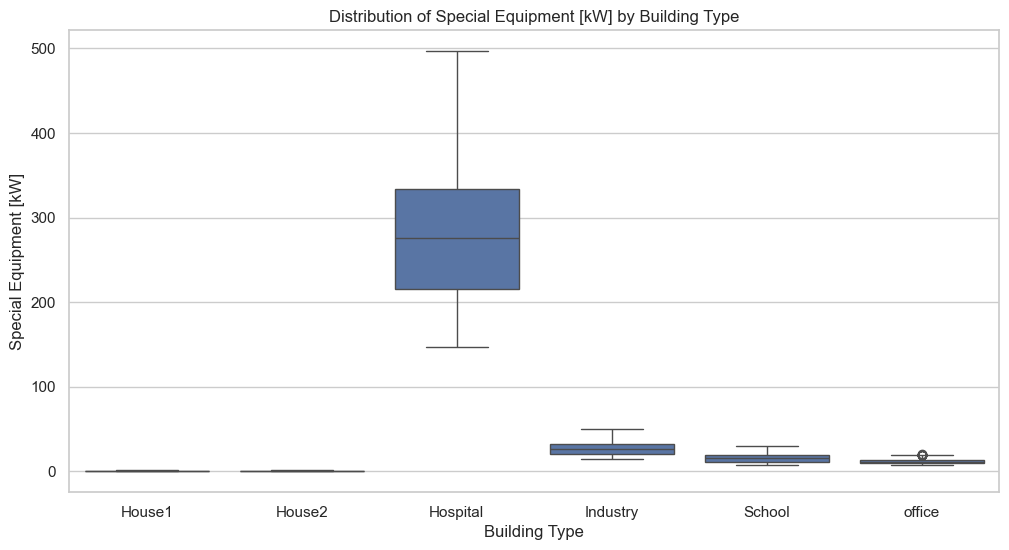

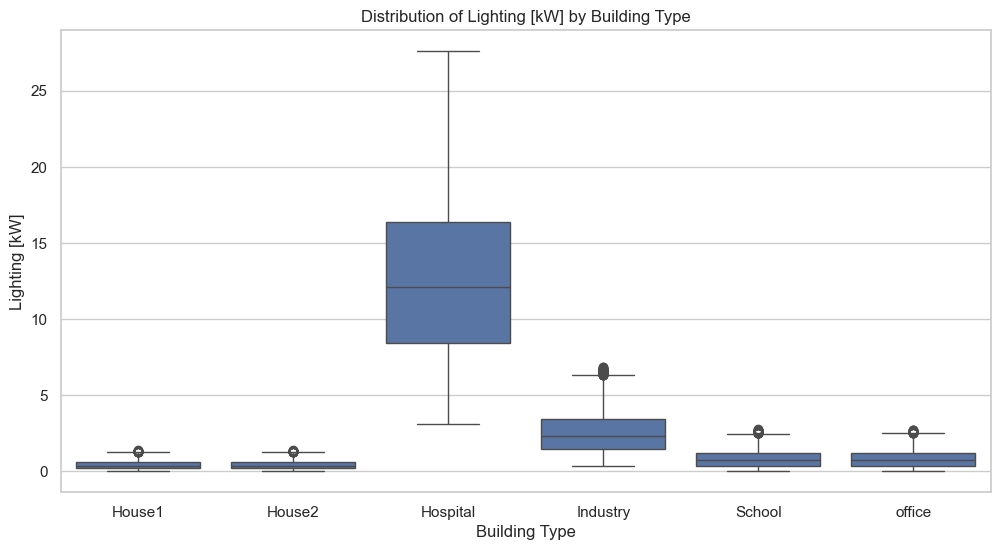

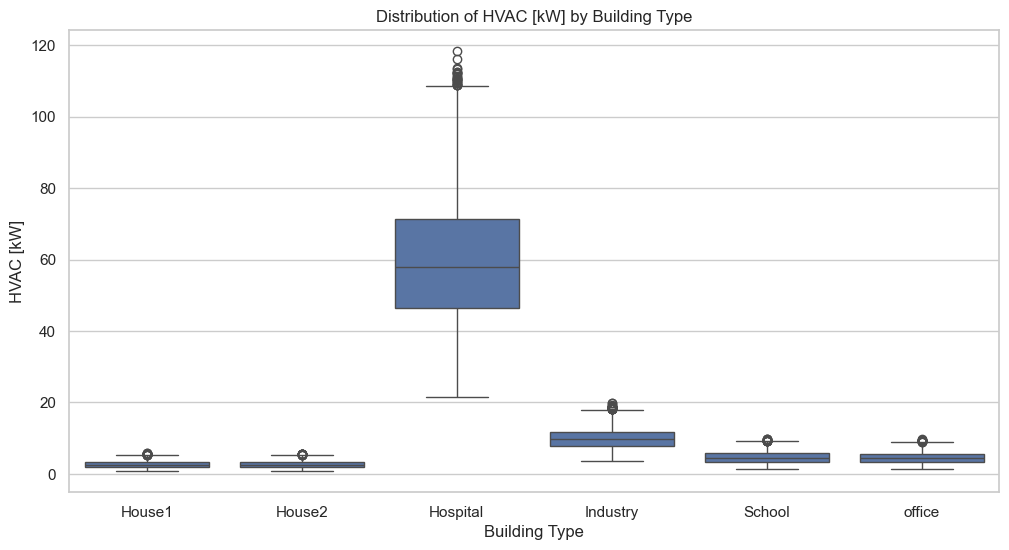

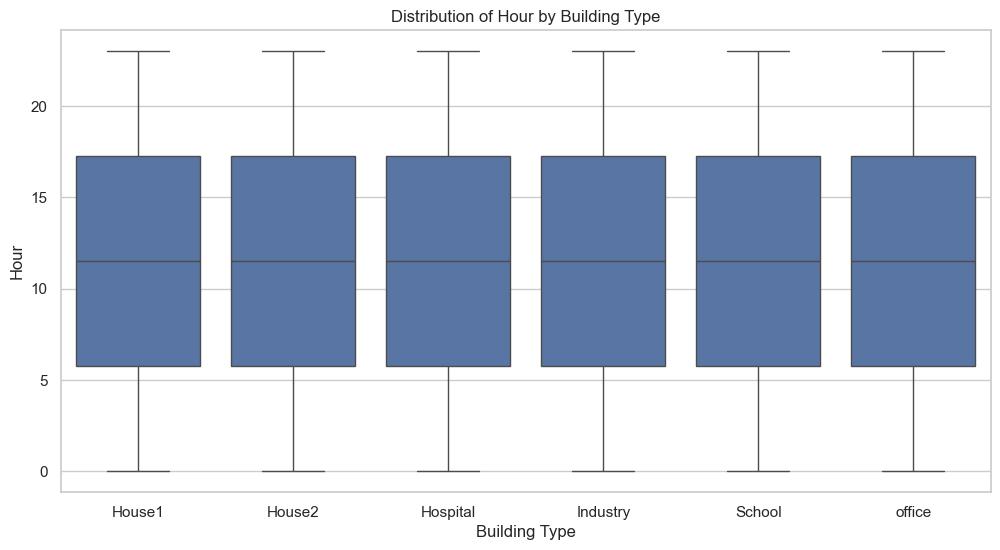

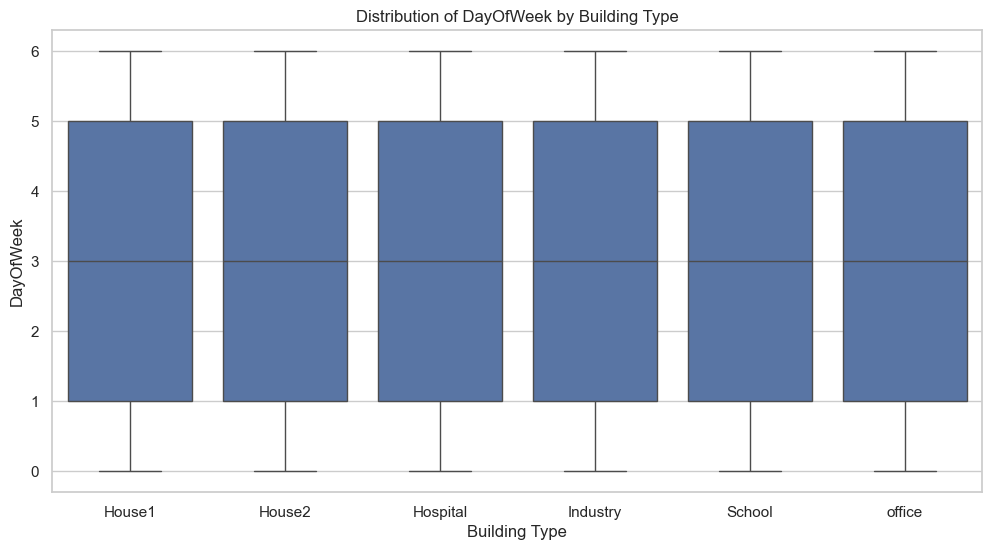

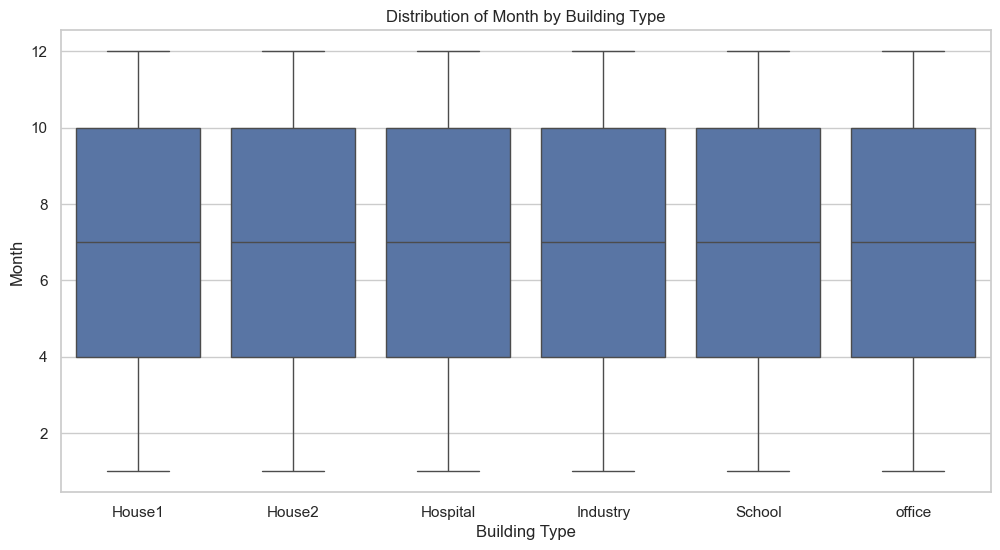

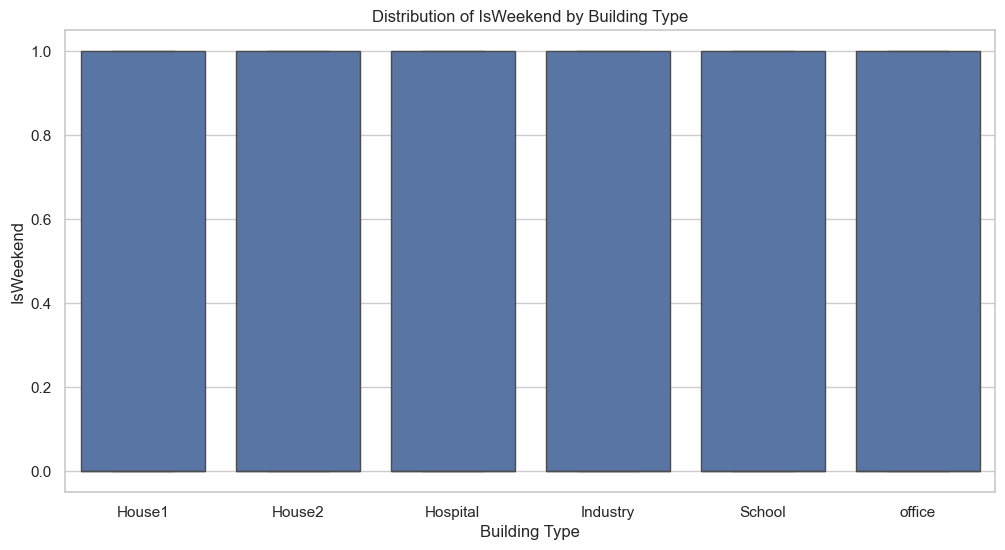

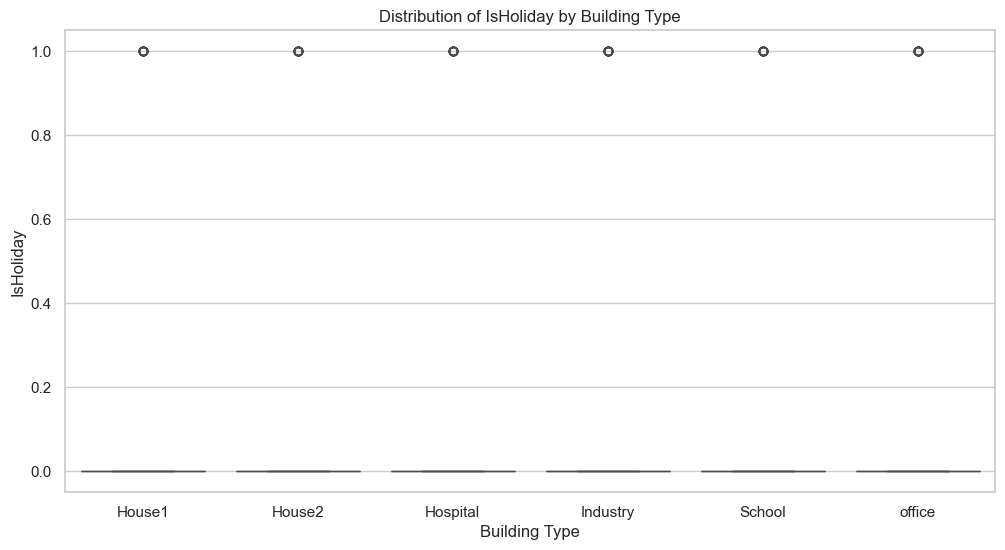

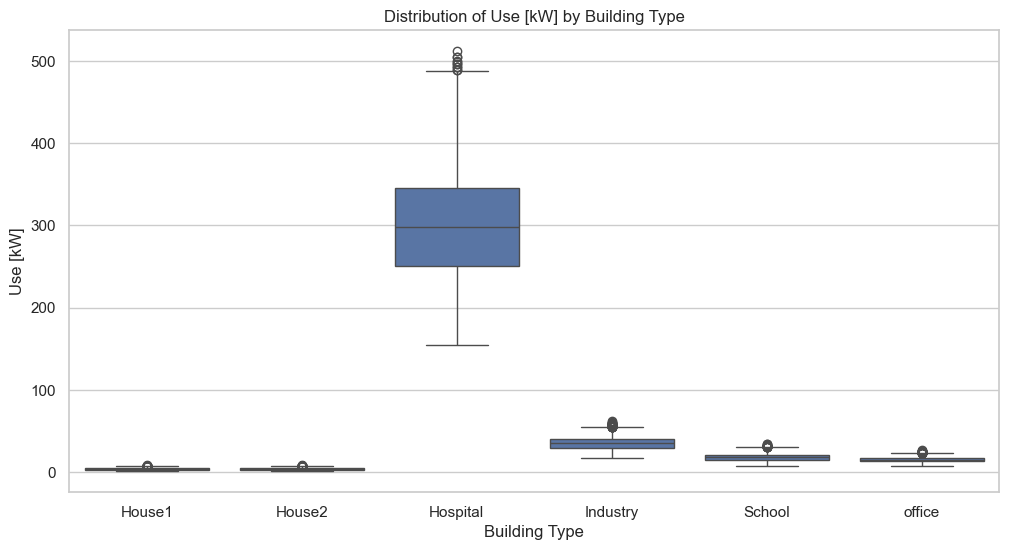

In [11]:
# Compare feature distributions
for feature in features[1:]:
    plt.figure(figsize=(12, 6))
    sns.boxplot(data=combined_data, x='Building Type', y=feature)
    plt.title(f'Distribution of {feature} by Building Type')
    plt.xlabel('Building Type')
    plt.ylabel(feature)
    plt.show()


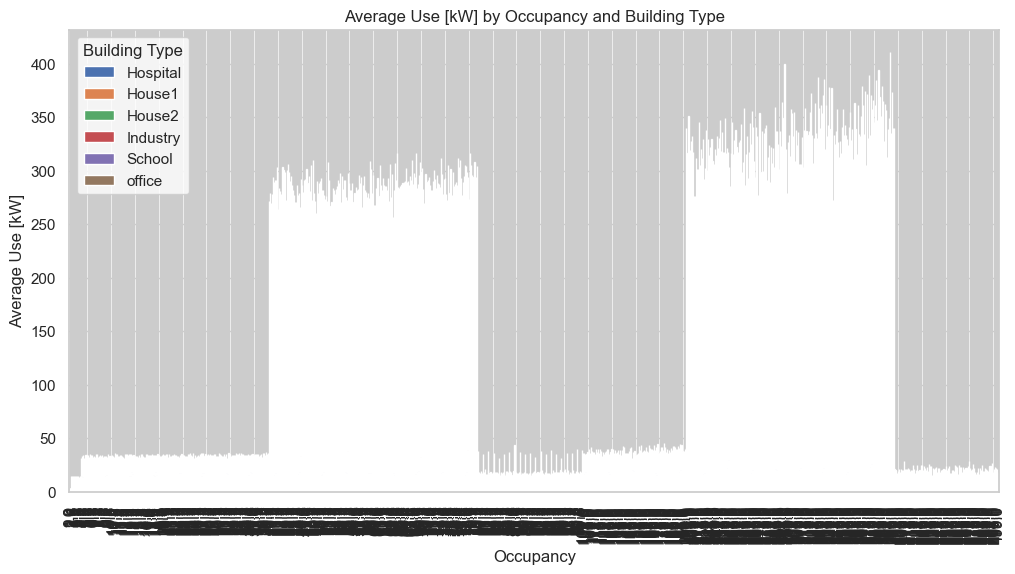

In [13]:
# Group by occupancy and building type
occupancy_analysis = combined_data.groupby(['Occupancy', 'Building Type'])[target].mean().unstack()
occupancy_analysis.plot(kind='bar', figsize=(12, 6))
plt.title('Average Use [kW] by Occupancy and Building Type')
plt.ylabel('Average Use [kW]')
plt.show()


C:\Users\haide\AppData\Local\Temp\ipykernel_16092\1698422815.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis')


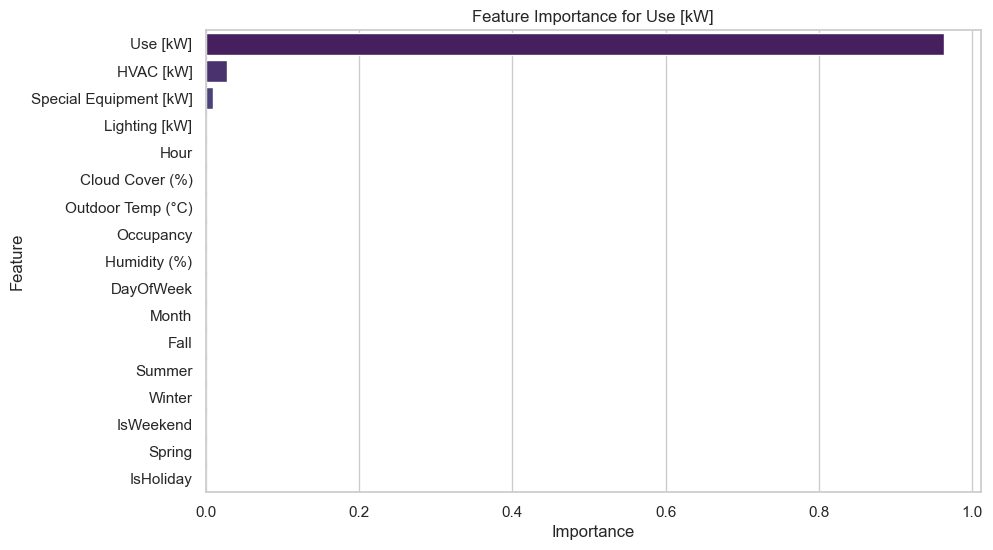

In [14]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

# Feature importance analysis
X = combined_data[features[1:]]
y = combined_data[target]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train a random forest regressor
model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)

# Feature importance
importances = model.feature_importances_
importance_df = pd.DataFrame({'Feature': features[1:], 'Importance': importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# Plot feature importance
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis')
plt.title('Feature Importance for Use [kW]')
plt.show()


In [15]:
# Assuming 'features' contains all your feature names including 'Use [kW]'
features = ['Time', 'Winter', 'Spring', 'Summer', 'Fall', 'Outdoor Temp (Â°C)', 
            'Humidity (%)', 'Cloud Cover (%)', 'Occupancy', 'Special Equipment [kW]', 
            'Lighting [kW]', 'HVAC [kW]', 'Hour', 'DayOfWeek', 'Month', 
            'IsWeekend', 'IsHoliday', 'Use [kW]']  # Include all feature names

# Feature importance
importances = model.feature_importances_

# Create DataFrame excluding 'Use [kW]'
importance_df = pd.DataFrame({'Feature': features[:-1], 'Importance': importances[:-1]})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# Visualize feature importance
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df)
plt.title('Feature Importance Excluding Target Variable')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.show()


ValueError: All arrays must be of the same length

In [5]:
import pandas as pd

# Load your datasets (replace with actual file paths)
house1_data = pd.read_csv("House1_data.csv")
house2_data = pd.read_csv("House2_data.csv")
hospital_data = pd.read_csv("Hospital_data.csv")
industry_data = pd.read_csv("Industry_data.csv")
office_data = pd.read_csv("Office_data.csv")
school_data = pd.read_csv("School_data.csv")

# Inspect the first few rows of each dataset
datasets = [house1_data, house2_data, hospital_data, industry_data, office_data, school_data]
for idx, data in enumerate(datasets):
    print(f"Dataset {idx + 1} - First 5 rows:")
    print(data.head(), "\n")


Dataset 1 - First 5 rows:
              Time  Winter  Spring  Summer  Fall  Outdoor Temp (°C)  \
0  01/01/2023 0:00       1       0       0     0          27.195497   
1  01/01/2023 1:00       1       0       0     0          -5.493332   
2  01/01/2023 2:00       1       0       0     0          16.297840   
3  01/01/2023 3:00       1       0       0     0          19.096822   
4  01/01/2023 4:00       1       0       0     0          38.755574   

   Humidity (%)  Cloud Cover (%)  Occupancy  Special Equipment [kW]  \
0     42.243703        30.426594          1                0.587585   
1     44.241643        16.055523          3                0.222906   
2     47.208378        17.883253          3                0.800850   
3     74.081312        25.598962          3                0.319166   
4     43.302587        65.988628          2                0.599125   

   Lighting [kW]  HVAC [kW]  Hour  DayOfWeek  Month  IsWeekend  IsHoliday  \
0       0.286283   1.794157     0          

In [6]:
for idx, data in enumerate(datasets):
    print(f"Dataset {idx + 1} - Data Types and Missing Values:")
    print(data.info())
    print(data.isnull().sum(), "\n")


Dataset 1 - Data Types and Missing Values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Time                    8760 non-null   object 
 1   Winter                  8760 non-null   int64  
 2   Spring                  8760 non-null   int64  
 3   Summer                  8760 non-null   int64  
 4   Fall                    8760 non-null   int64  
 5   Outdoor Temp (°C)       8760 non-null   float64
 6   Humidity (%)            8760 non-null   float64
 7   Cloud Cover (%)         8760 non-null   float64
 8   Occupancy               8760 non-null   int64  
 9   Special Equipment [kW]  8760 non-null   float64
 10  Lighting [kW]           8760 non-null   float64
 11  HVAC [kW]               8760 non-null   float64
 12  Hour                    8760 non-null   int64  
 13  DayOfWeek               8760 non-null   int64  
 1

In [7]:
for idx, data in enumerate(datasets):
    print(f"Dataset {idx + 1} - Descriptive Statistics:")
    print(data.describe(), "\n")


Dataset 1 - Descriptive Statistics:
            Winter       Spring       Summer         Fall  Outdoor Temp (°C)  \
count  8760.000000  8760.000000  8760.000000  8760.000000        8760.000000   
mean      0.250000     0.250000     0.250000     0.250000          17.562969   
std       0.433037     0.433037     0.433037     0.433037          14.606312   
min       0.000000     0.000000     0.000000     0.000000          -7.993369   
25%       0.000000     0.000000     0.000000     0.000000           4.857658   
50%       0.000000     0.000000     0.000000     0.000000          17.515143   
75%       0.250000     0.250000     0.250000     0.250000          30.266439   
max       1.000000     1.000000     1.000000     1.000000          42.993630   

       Humidity (%)  Cloud Cover (%)    Occupancy  Special Equipment [kW]  \
count   8760.000000      8760.000000  8760.000000             8760.000000   
mean      70.249493        49.226845     1.997374                0.449497   
std       17

<Figure size 1500x1000 with 0 Axes>

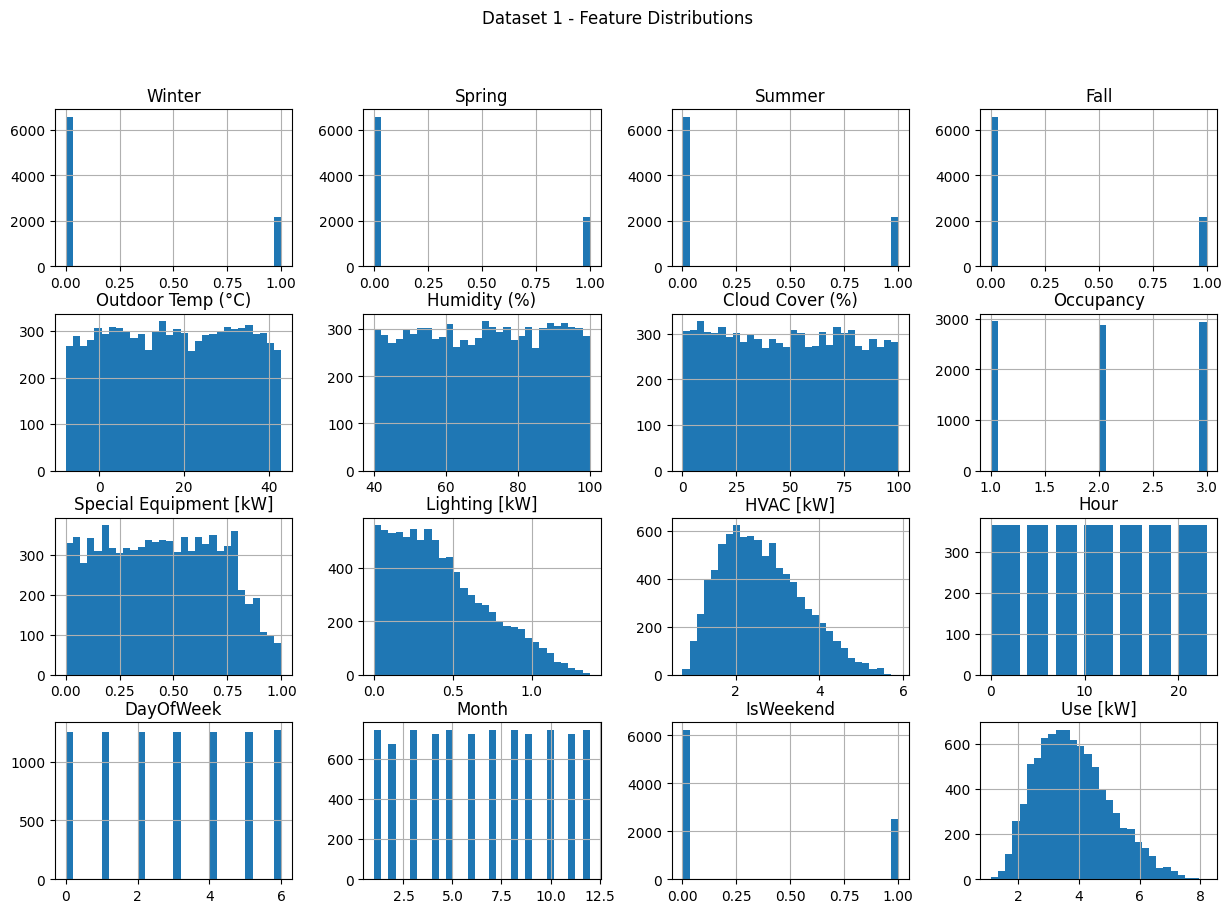

<Figure size 1500x1000 with 0 Axes>

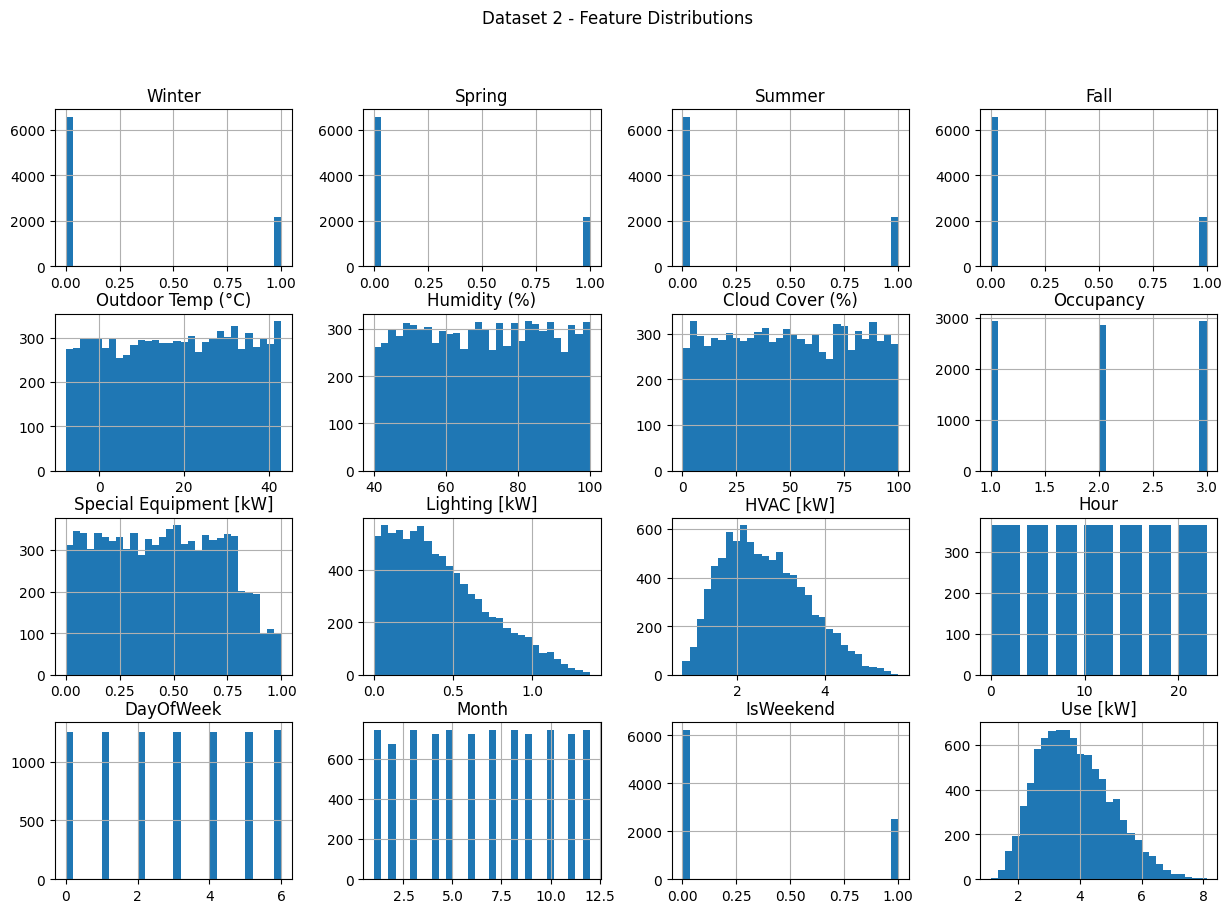

<Figure size 1500x1000 with 0 Axes>

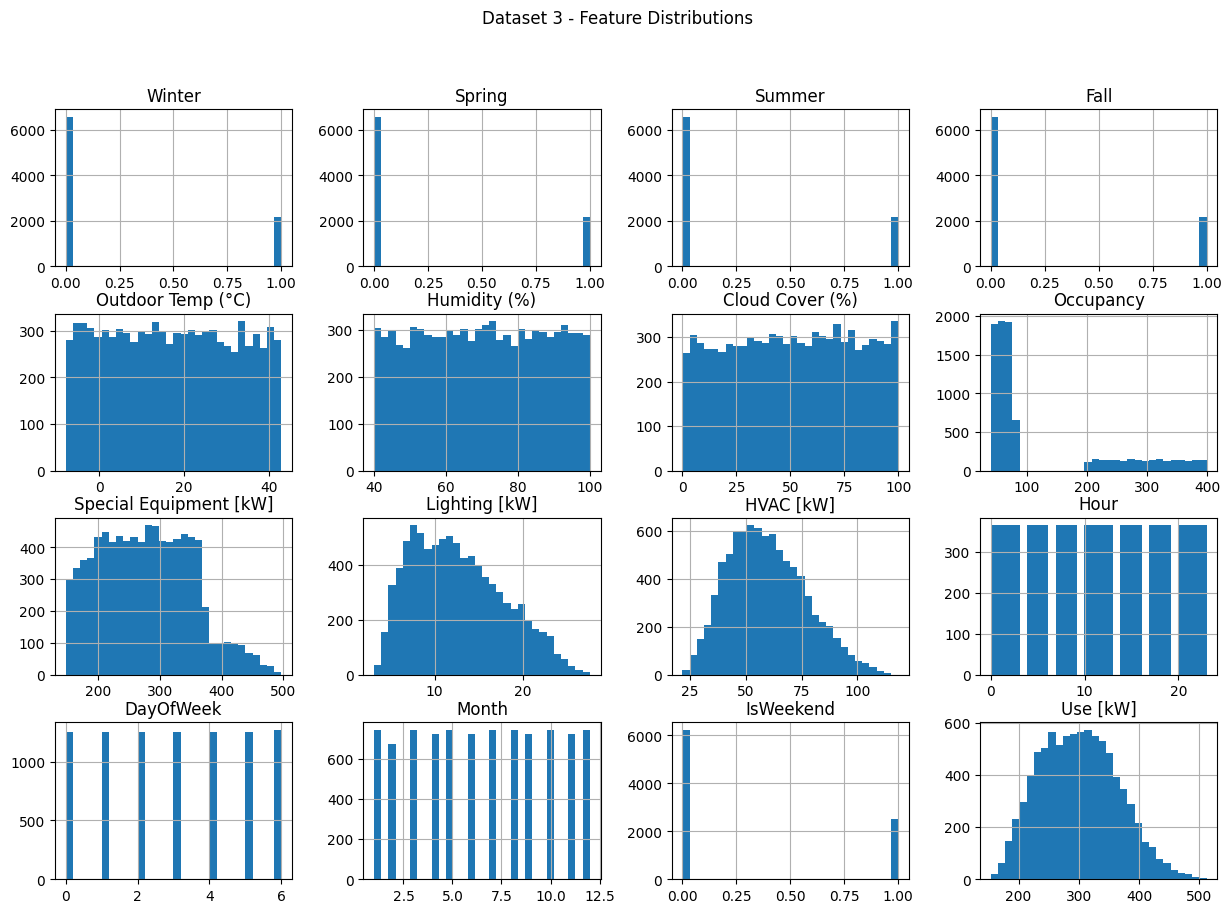

<Figure size 1500x1000 with 0 Axes>

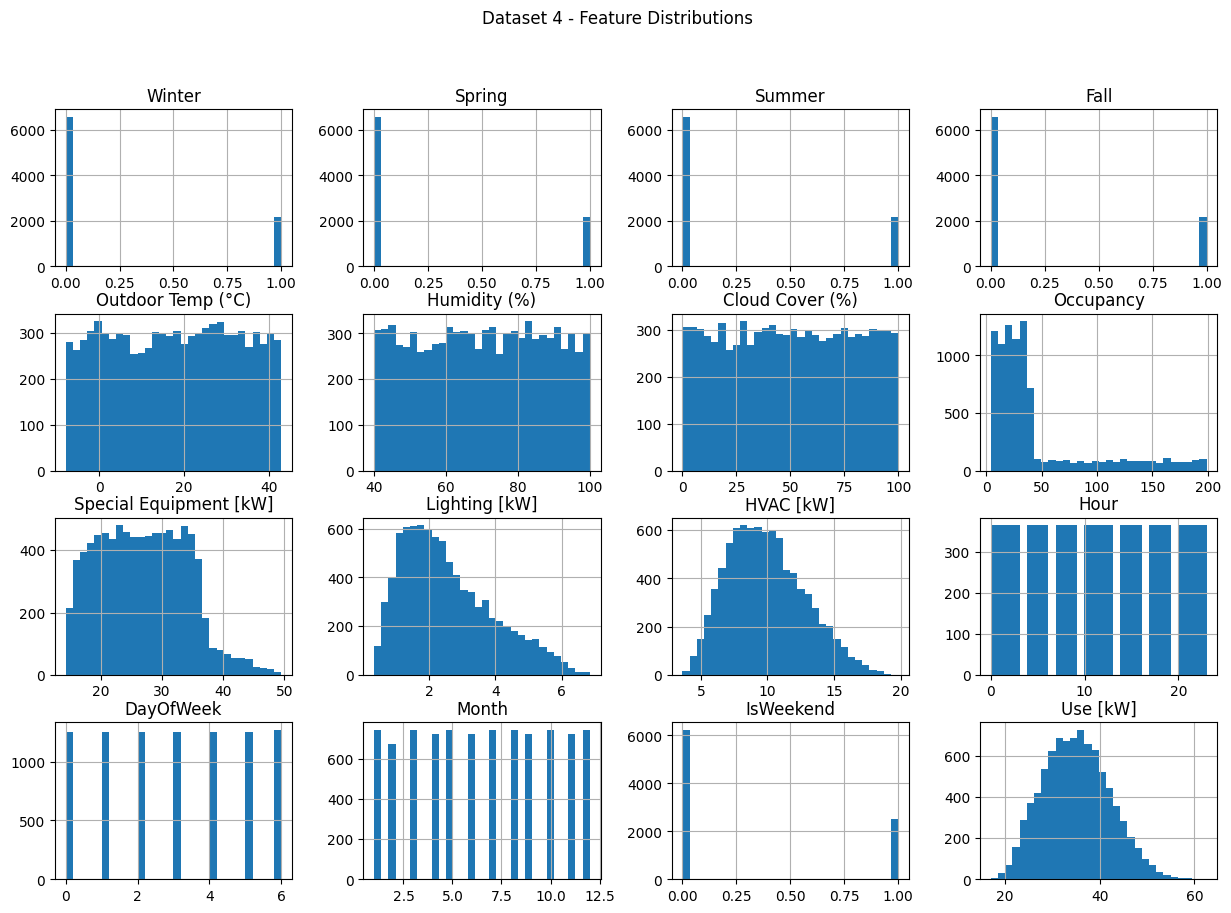

<Figure size 1500x1000 with 0 Axes>

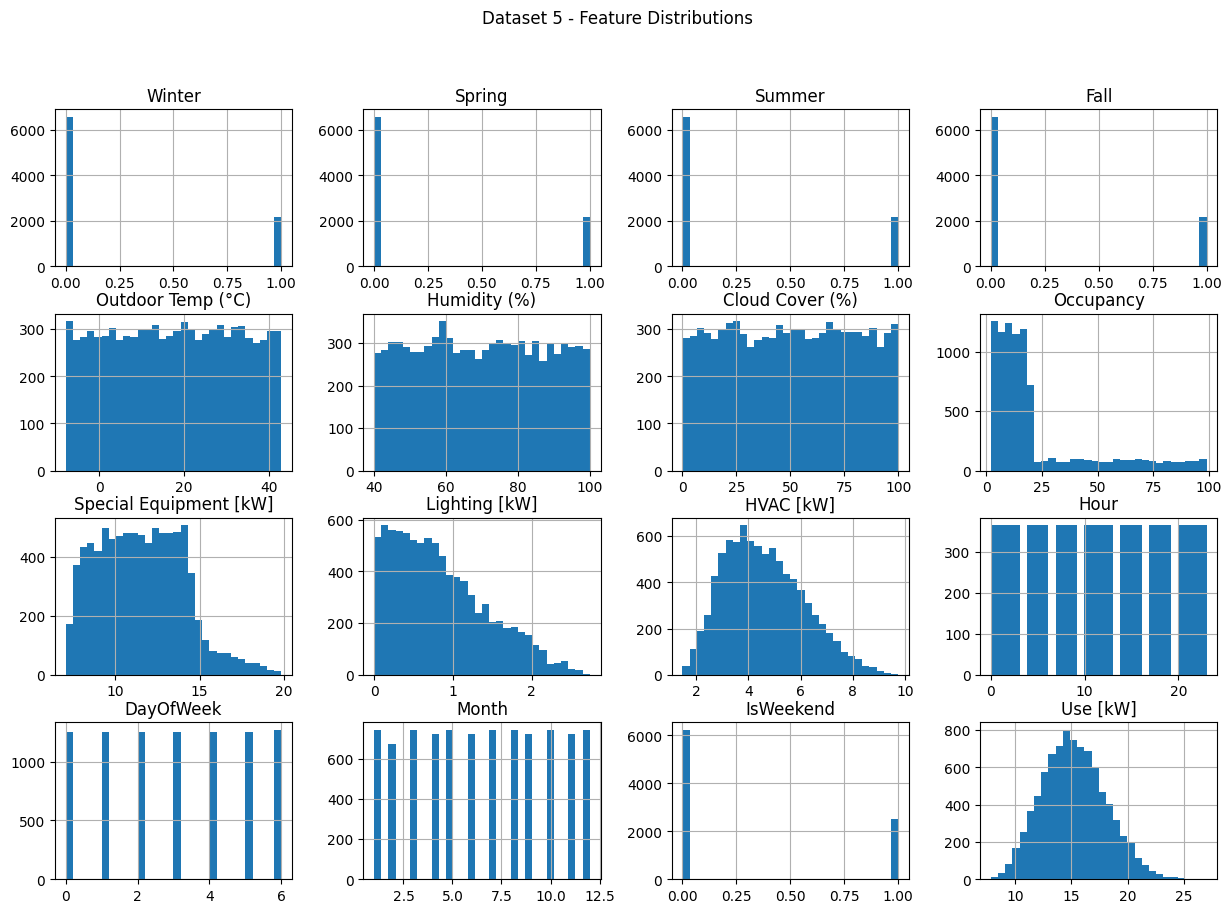

<Figure size 1500x1000 with 0 Axes>

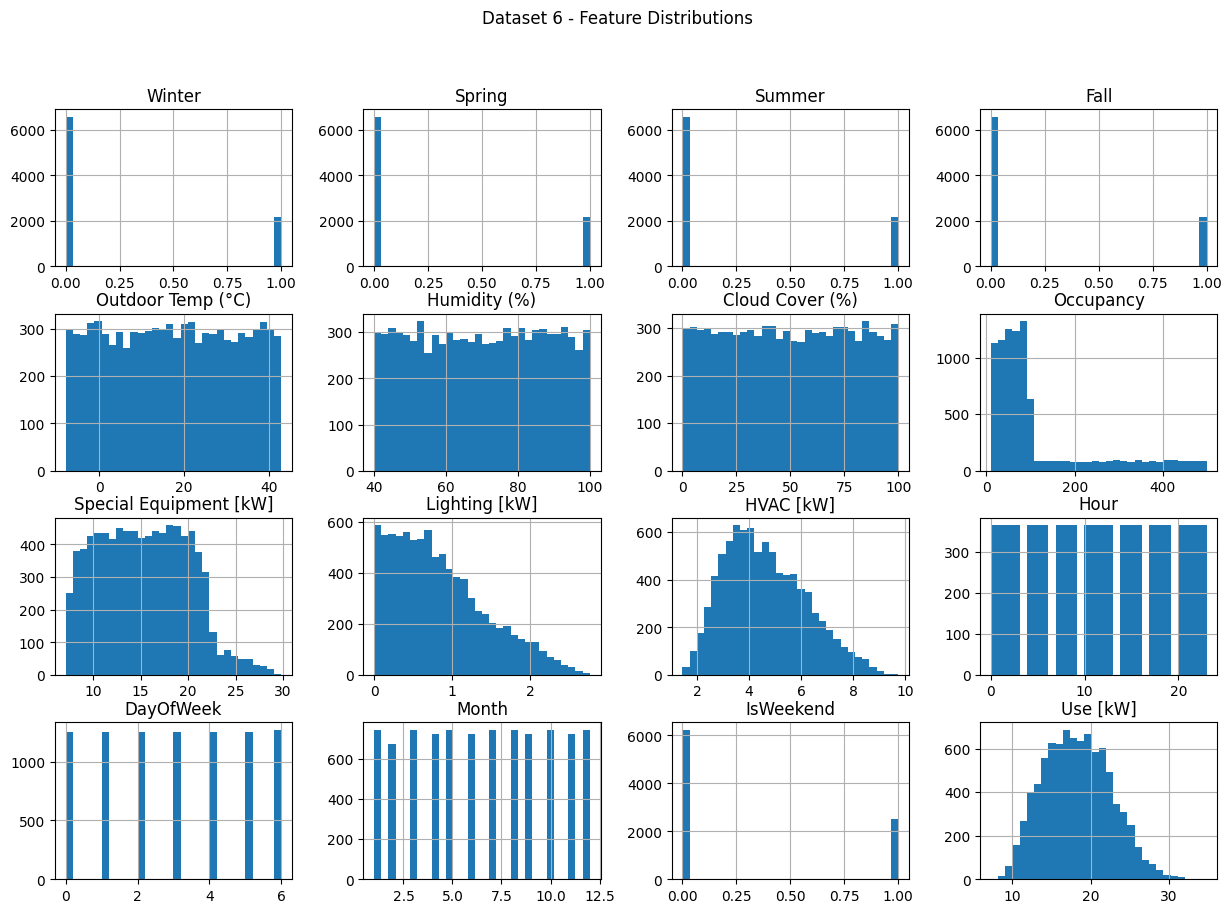

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize distributions for numerical features
for idx, data in enumerate(datasets):
    plt.figure(figsize=(15, 10))
    data.hist(bins=30, figsize=(15, 10))
    plt.suptitle(f'Dataset {idx + 1} - Feature Distributions')
    plt.show()


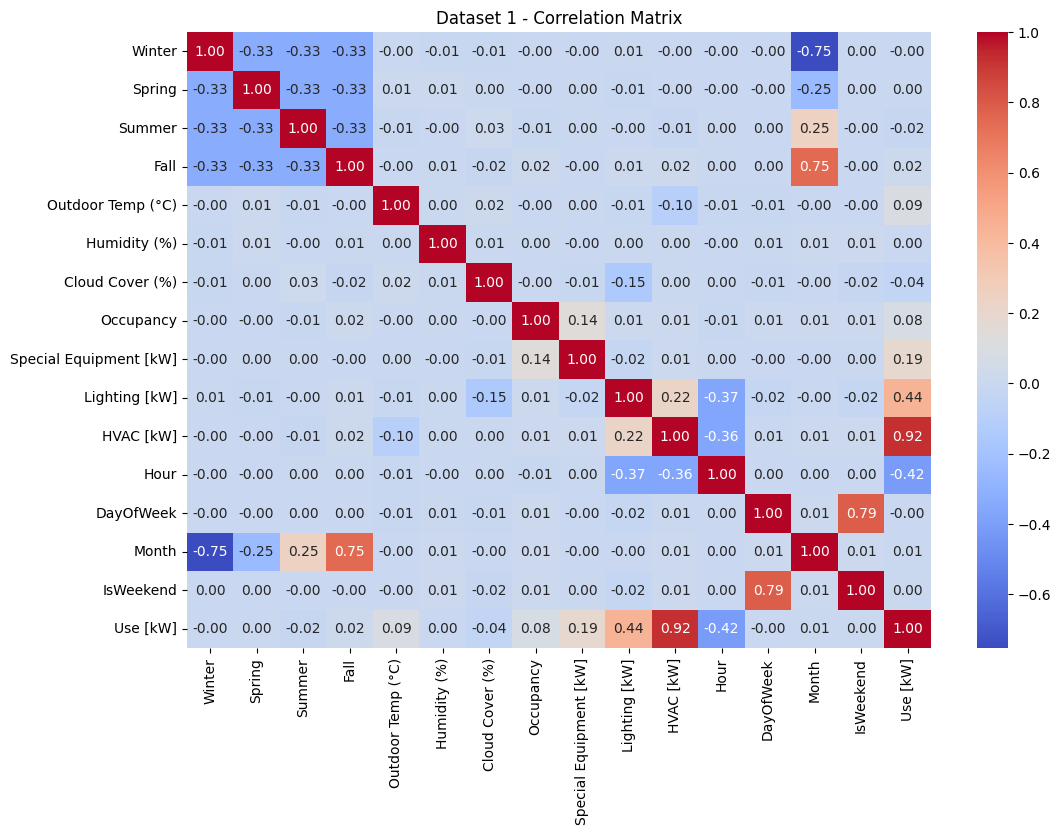

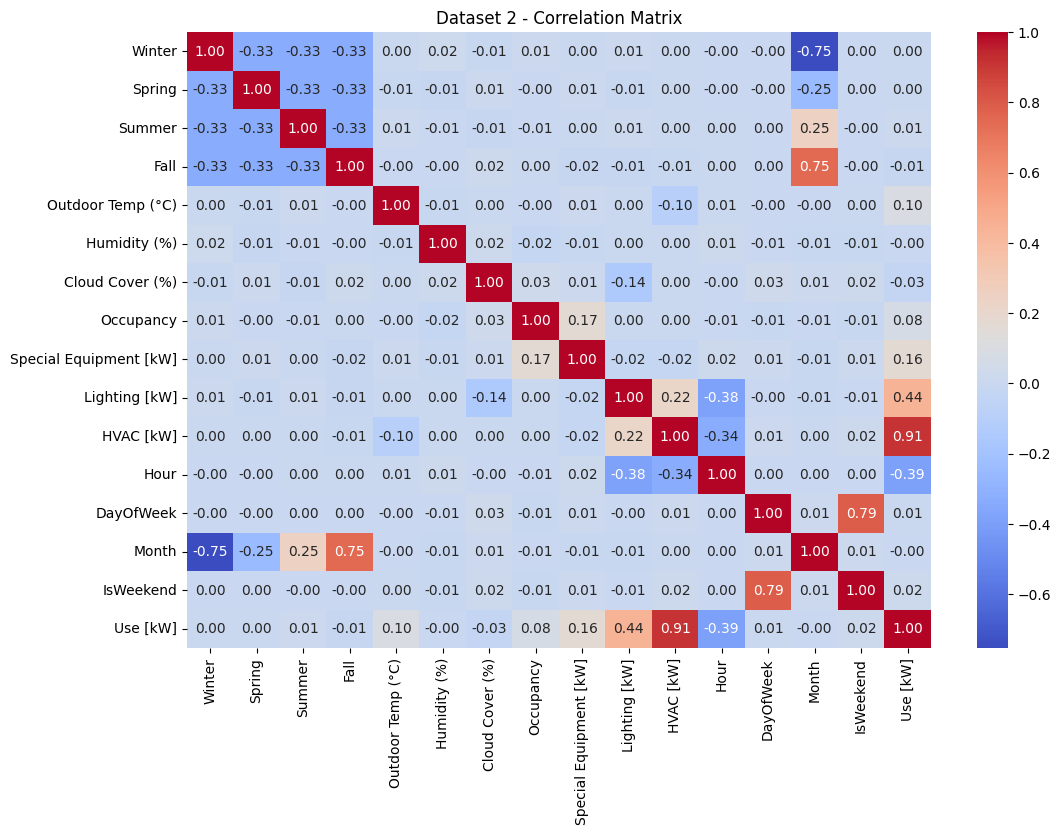

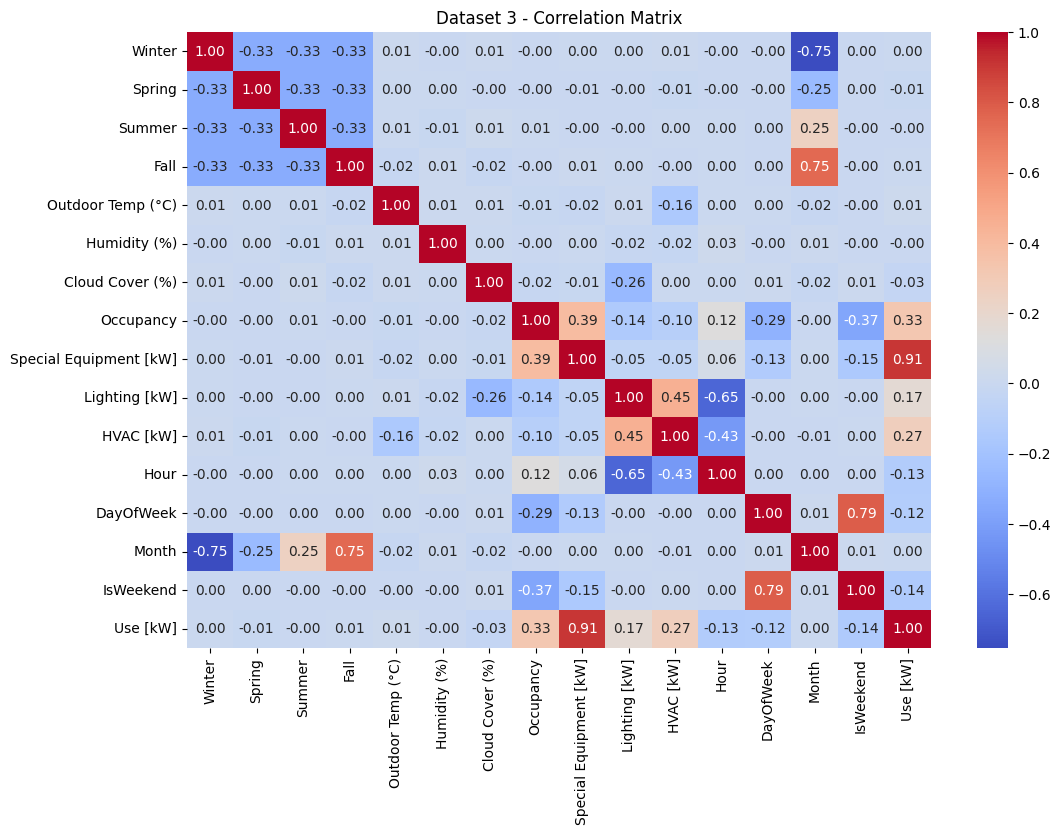

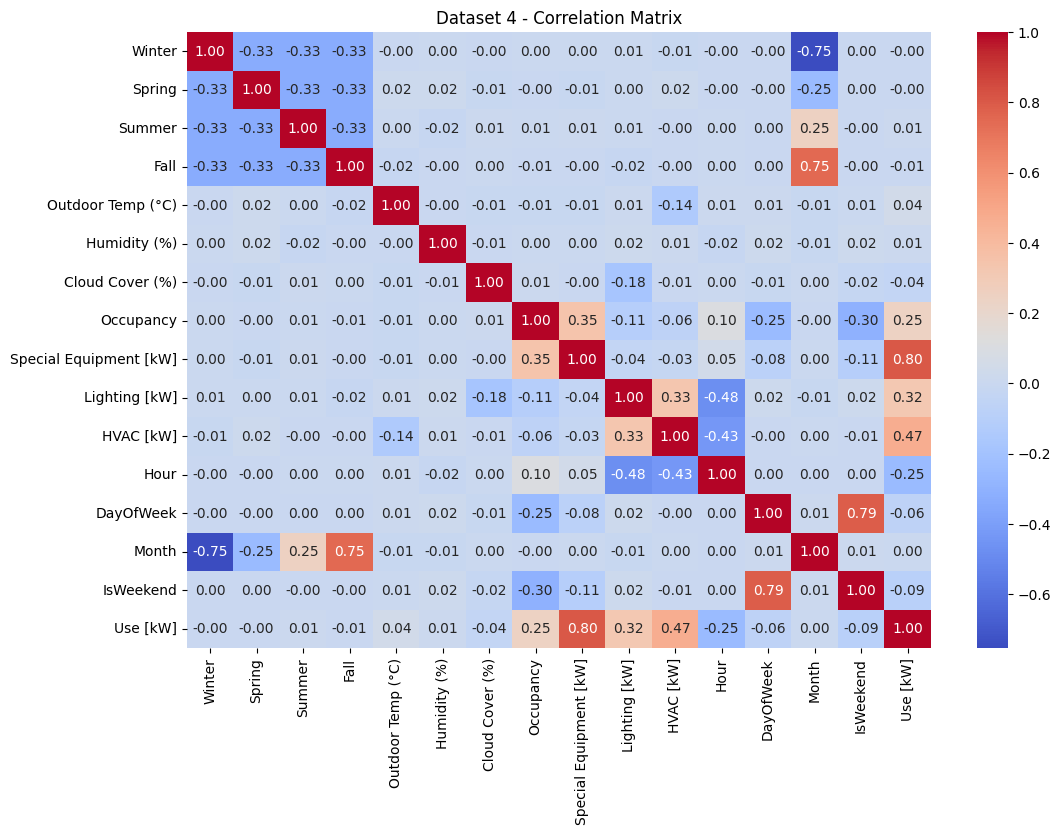

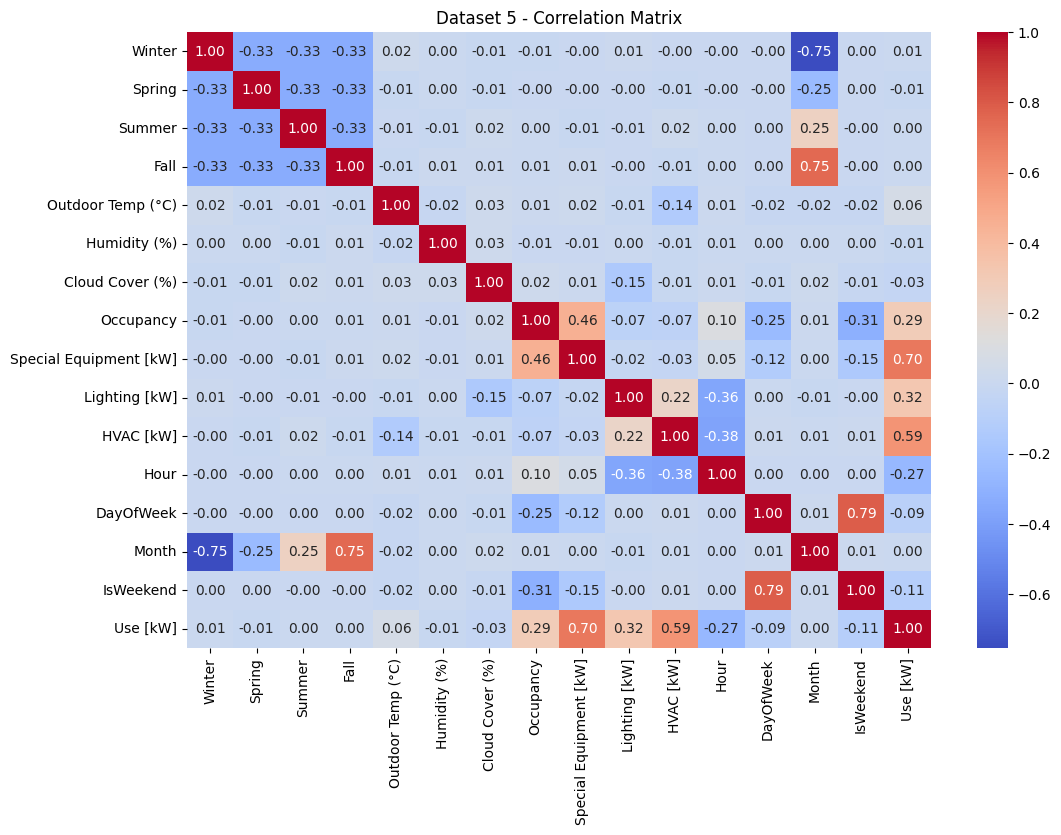

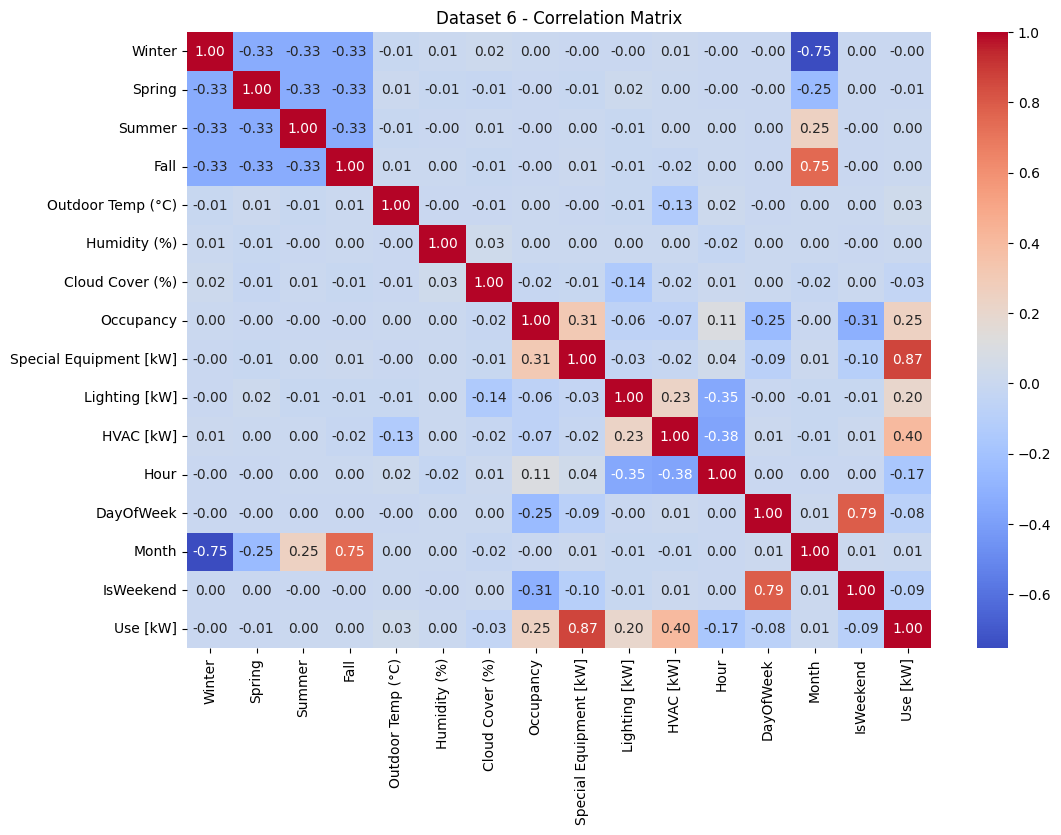

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Correlation Analysis
for idx, data in enumerate(datasets):
    # Exclude non-numeric columns
    numeric_data = data.select_dtypes(include=['float64', 'int64'])
    
    # Calculate correlation matrix
    correlation_matrix = numeric_data.corr()
    
    # Plot the heatmap
    plt.figure(figsize=(12, 8))
    sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm')
    plt.title(f'Dataset {idx + 1} - Correlation Matrix')
    plt.show()


In [11]:
for idx, data in enumerate(datasets):
    duplicates = data.duplicated().sum()
    print(f"Dataset {idx + 1} - Duplicate Rows: {duplicates}")


Dataset 1 - Duplicate Rows: 0
Dataset 2 - Duplicate Rows: 0
Dataset 3 - Duplicate Rows: 0
Dataset 4 - Duplicate Rows: 0
Dataset 5 - Duplicate Rows: 0
Dataset 6 - Duplicate Rows: 0


ValueError: num must be an integer with 1 <= num <= 15, not 16

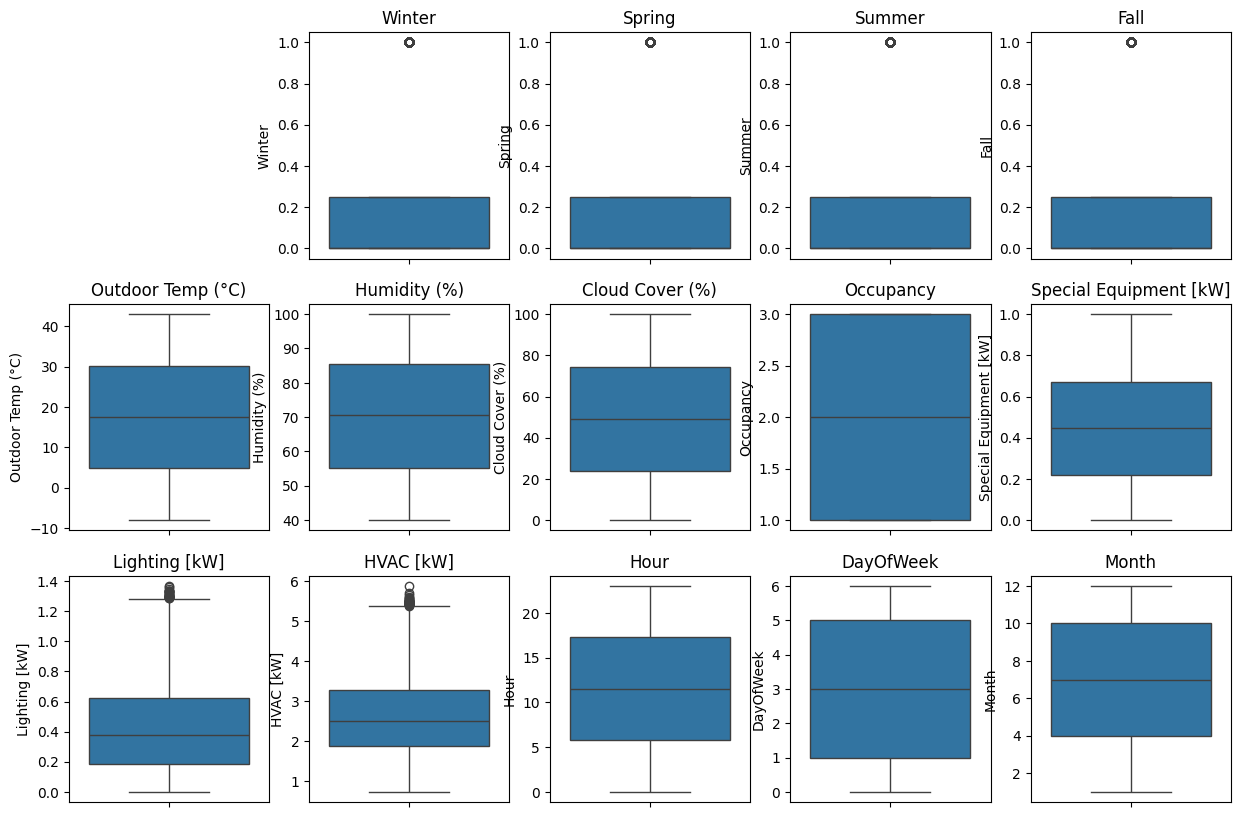

In [12]:
for idx, data in enumerate(datasets):
    plt.figure(figsize=(15, 10))
    for column in data.select_dtypes(include=['float64', 'int64']).columns:
        plt.subplot(3, 5, data.columns.get_loc(column) + 1)
        sns.boxplot(y=data[column])
        plt.title(column)
    plt.tight_layout()
    plt.suptitle(f'Dataset {idx + 1} - Outlier Detection')
    plt.show()


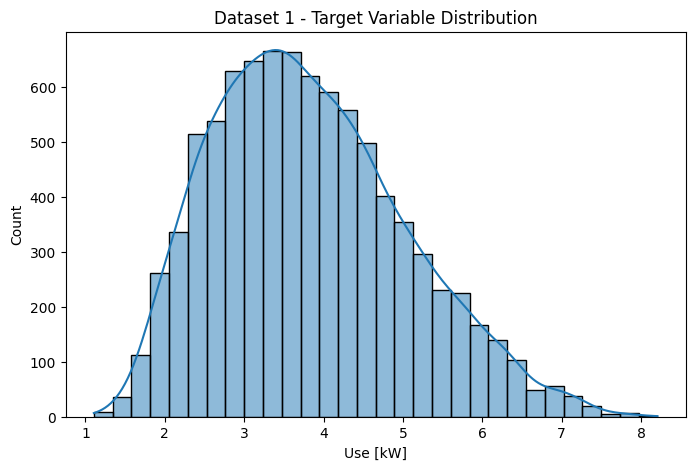

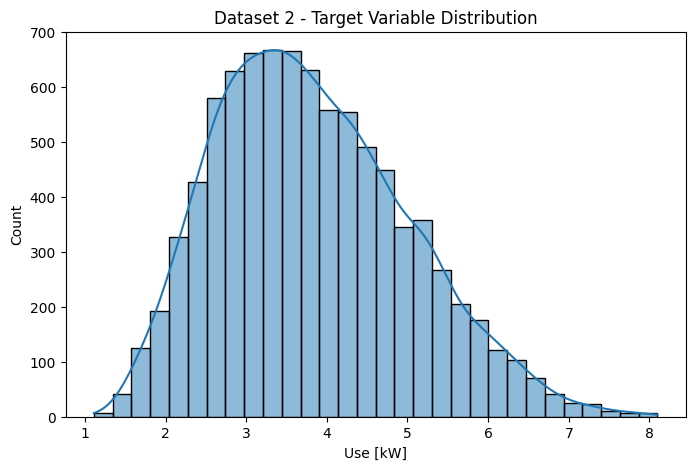

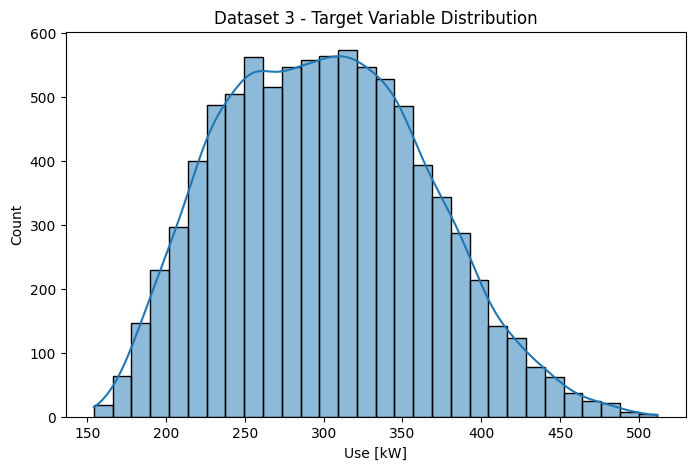

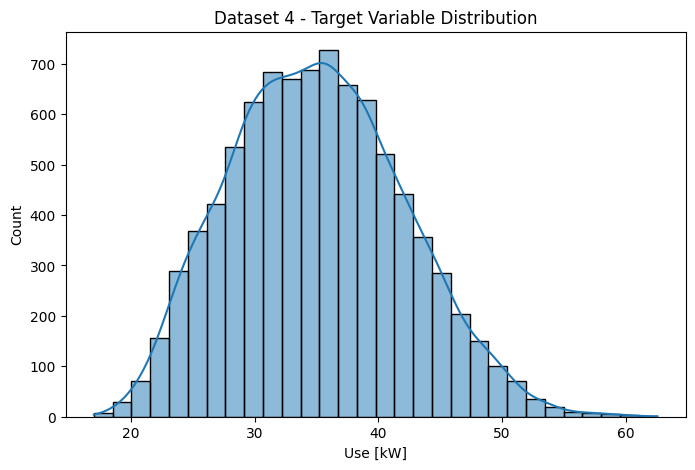

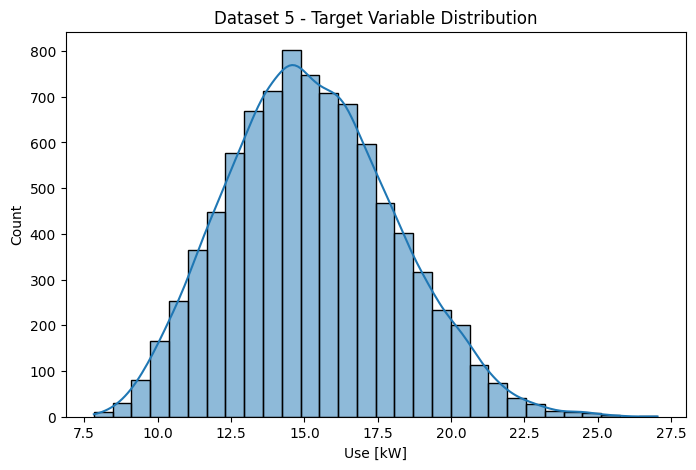

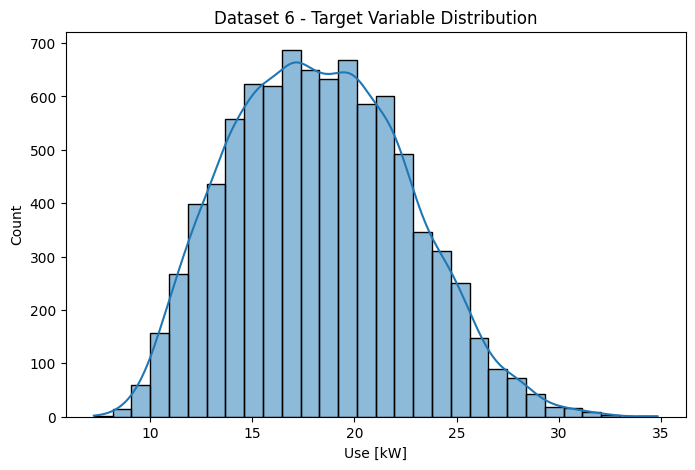

In [13]:
# Assuming 'Use [kW]' is the target variable in each dataset
for idx, data in enumerate(datasets):
    if 'Use [kW]' in data.columns:
        plt.figure(figsize=(8, 5))
        sns.histplot(data['Use [kW]'], bins=30, kde=True)
        plt.title(f'Dataset {idx + 1} - Target Variable Distribution')
        plt.show()


In [15]:
import pandas as pd

# Load your datasets (replace with actual file paths)
house1_data = pd.read_csv("House1_data.csv")
house2_data = pd.read_csv("House2_data.csv")
hospital_data = pd.read_csv("Hospital_data.csv")
industry_data = pd.read_csv("Industry_data.csv")
office_data = pd.read_csv("Office_data.csv")
school_data = pd.read_csv("School_data.csv")

# List of datasets and the target feature name
datasets = [house1_data, house2_data, hospital_data, industry_data, office_data, school_data]
target_feature = "Use [kW]"  # Replace with the actual target feature name if different

# Dictionary to store correlation results
correlation_results = {}

# Calculate correlations
for i, data in enumerate(datasets):
    # Check if the target feature exists in the dataset
    if target_feature in data.columns:
        # Drop non-numeric columns (like 'Time' or any other non-numeric columns)
        numeric_data = data.select_dtypes(include=['number'])
        
        # Calculate the correlation with the target feature
        if target_feature in numeric_data.columns:
            correlations = numeric_data.corr()[target_feature]
            # Store correlations excluding the target feature itself
            correlation_results[f'Dataset {i + 1}'] = correlations.drop(target_feature)

# Convert the results into a DataFrame for better visualization
correlation_df = pd.DataFrame(correlation_results)

# Find the feature with the highest correlation for each dataset
highest_correlations = correlation_df.idxmax()
highest_correlations_values = correlation_df.max()

# Combine results into a final DataFrame
final_results = pd.DataFrame({
    'Feature': highest_correlations,
    'Correlation': highest_correlations_values
})

print(final_results)


                          Feature  Correlation
Dataset 1               HVAC [kW]     0.917970
Dataset 2               HVAC [kW]     0.913228
Dataset 3  Special Equipment [kW]     0.910384
Dataset 4  Special Equipment [kW]     0.801443
Dataset 5  Special Equipment [kW]     0.698472
Dataset 6  Special Equipment [kW]     0.867024


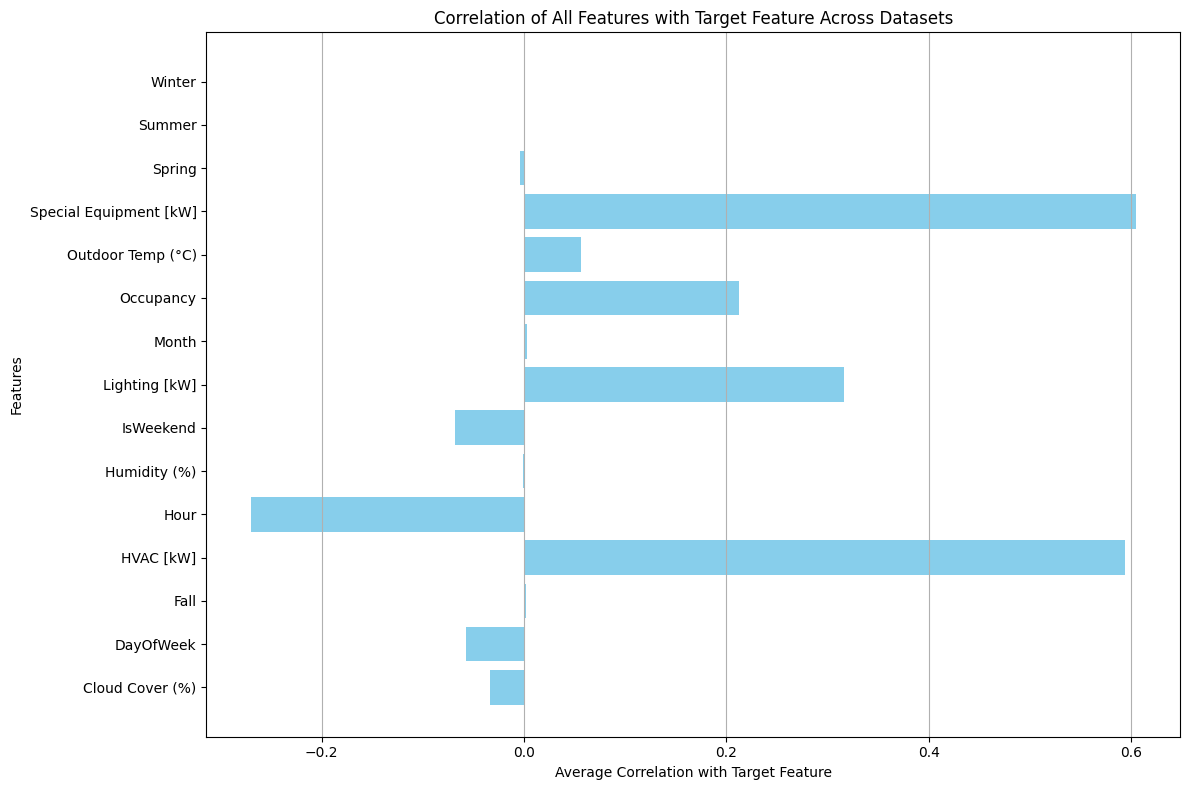

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

# Load your datasets (replace with actual file paths)
house1_data = pd.read_csv("House1_data.csv")
house2_data = pd.read_csv("House2_data.csv")
hospital_data = pd.read_csv("Hospital_data.csv")
industry_data = pd.read_csv("Industry_data.csv")
office_data = pd.read_csv("Office_data.csv")
school_data = pd.read_csv("School_data.csv")

# List of datasets and the target feature name
datasets = [house1_data, house2_data, hospital_data, industry_data, office_data, school_data]
target_feature = "Use [kW]"  # Replace with the actual target feature name if different

# List to store correlation results
correlation_results = []

# Calculate correlations
for i, data in enumerate(datasets):
    # Check if the target feature exists in the dataset
    if target_feature in data.columns:
        # Drop non-numeric columns (like 'Time' or any other non-numeric columns)
        numeric_data = data.select_dtypes(include=['number'])
        
        # Calculate the correlation with the target feature
        if target_feature in numeric_data.columns:
            correlations = numeric_data.corr()[target_feature]
            # Store all feature correlations with the target feature
            for feature, correlation in correlations.items():
                if feature != target_feature:  # Exclude the target feature itself
                    correlation_results.append({'Dataset': f'Dataset {i + 1}', 'Feature': feature, 'Correlation': correlation})

# Convert the results into a DataFrame for better visualization
correlation_df = pd.DataFrame(correlation_results)

# Aggregate correlation results to see the total correlation for each feature
aggregated_correlation = correlation_df.groupby('Feature')['Correlation'].mean().reset_index()

# Plot all features and their correlation with the target feature
plt.figure(figsize=(12, 8))
plt.barh(aggregated_correlation['Feature'], aggregated_correlation['Correlation'], color='skyblue')
plt.xlabel('Average Correlation with Target Feature')
plt.ylabel('Features')
plt.title('Correlation of All Features with Target Feature Across Datasets')
plt.grid(axis='x')
plt.tight_layout()
plt.show()


In [18]:
import pandas as pd
import os

def encode_is_holiday(filepaths):
    """
    Encode the 'IsHoliday' column in multiple datasets.
    
    Args:
    - filepaths (list): List of file paths to the datasets.
    
    Returns:
    - None: Saves the updated datasets back to the same files.
    """
    for filepath in filepaths:
        # Load the dataset
        df = pd.read_csv(filepath)
        
        # Check if 'IsHoliday' column exists
        if 'IsHoliday' in df.columns:
            # Convert 'IsHoliday' to numeric format (1 for TRUE, 0 for FALSE)
            df['IsHoliday'] = df['IsHoliday'].map({'TRUE': 1, 'FALSE': 0})
            
            # Save the updated dataset back to the same file
            df.to_csv(filepath, index=False)
            print(f"Updated 'IsHoliday' column in {filepath}")
        else:
            print(f"'IsHoliday' column not found in {filepath}. Skipping.")

# List of file paths to your datasets
filepaths = [
    
    "Hospital_data.csv",
    "House1_data.csv",
    "House2_data.csv",
    "Industry_data.csv",
    "Office_data.csv",
    "School_data.csv"
]

# Call the function
encode_is_holiday(filepaths)

Updated 'IsHoliday' column in Hospital_data.csv
Updated 'IsHoliday' column in House1_data.csv
Updated 'IsHoliday' column in House2_data.csv
Updated 'IsHoliday' column in Industry_data.csv
Updated 'IsHoliday' column in Office_data.csv
Updated 'IsHoliday' column in School_data.csv


In [ ]:
import pandas as pd

# Read the data
df = pd.read_csv('Hospital_data.csv')  # Replace with your actual file path

# Convert IsHoliday to numeric
df['IsHoliday'] = df['IsHoliday'].map({'TRUE': 1, 'FALSE': 0})

# Save the modified dataset back to CSV
df.to_csv('your_file.csv', index=False)

In [24]:
import pandas as pd

def update_datasets(filepaths):
 
    for filepath in filepaths:
        # Load the dataset
        df = pd.read_csv(filepath)
        
        # Convert 'IsHoliday' column values
        if 'IsHoliday' in df.columns:
            df['IsHoliday'] = df['IsHoliday'].map({'TRUE': 1, 'FALSE': 0}).fillna(0)
        
        # Save the updated dataset back to the same file
        df.to_csv(filepath, index=False)
        print(f"Updated dataset saved to {filepath}")

# Example usage
filepaths = [
    
    "Hospital_data.csv",
    "House1_data.csv",
    "House2_data.csv",
    "Industry_data.csv",
    "Office_data.csv",
    "School_data.csv"
]
update_datasets(filepaths)


Updated dataset saved to Hospital_data.csv
Updated dataset saved to House1_data.csv
Updated dataset saved to House2_data.csv
Updated dataset saved to Industry_data.csv
Updated dataset saved to Office_data.csv
Updated dataset saved to School_data.csv


In [3]:
import pandas as pd
import numpy as np
import random

# Set random seed for reproducibility
random.seed(42)
np.random.seed(42)

# Constants
hours_per_year = 8760
building_types = ['Hospital', 'House1', 'House2', 'Industry', 'School', 'Office']
seasons = ['Winter', 'Spring', 'Summer', 'Fall']
temperature_range = (-8, 43)  # Outdoor temperature range in °C
humidity_range = (40, 100)     # Humidity range in %
cloud_cover_range = (0, 100)   # Cloud cover range in %

occupancy_range = {
    'Hospital': (200, 400),
    'House1': (1, 4),
    'House2': (1, 4),
    'Industry': (20, 200),
    'School': (50, 500),
    'Office': (10, 100)
}

special_equipment_range = {
    'Hospital': (200, 500),
    'House1': (0, 1),
    'House2': (0, 1),
    'Industry': (20, 50),
    'School': (10, 30),
    'Office': (10, 20)
}

lighting_range = {
    'Hospital': (10, 20),
    'House1': (0, 1),
    'House2': (0, 1),
    'Industry': (1, 5),
    'School': (0, 2),
    'Office': (0, 2)
}

hvac_range = {
    'Hospital': (30, 60),
    'House1': (1, 3),
    'House2': (1, 3),
    'Industry': (5, 10),
    'School': (2, 5),
    'Office': (2, 5)
}

def add_temporal_features(df):
    df['Hour'] = df['Time'].dt.hour
    df['DayOfWeek'] = df['Time'].dt.dayofweek
    df['Month'] = df['Time'].dt.month
    df['IsWeekend'] = df['DayOfWeek'].isin([5, 6]).astype(int)
    df['IsHoliday'] = (df['Time'].dt.month == 12) & (df['Time'].dt.day == 25)  # Example holiday
    df['IsHoliday'] = df['IsHoliday'].astype(int)  # Convert to integer (1 or 0)

    return df

def add_usage_patterns(df, building_type):
    # Business hours pattern (except for residential)
    if building_type not in ['House1', 'House2']:
        business_hours = (df['Hour'].between(9, 17)) & (~df['IsWeekend'])
        df['Occupancy'] = np.where(business_hours, 
                                 df['Occupancy'], 
                                 df['Occupancy'] * 0.2)  # Lower occupancy outside business hours
    
    # Temperature-dependent HVAC usage
    df['HVAC [kW]'] = df['HVAC [kW]'] * (
        1 + 0.3 * np.sin(np.pi * df['Hour'] / 12) +  # Daily cycle
        0.5 * (df['Outdoor Temp (°C)'] - 20).abs() / 20  # Temperature impact
    )
    
    return df

def add_feature_correlations(df):
    # Lighting correlates with cloud cover and time of day
    df['Lighting [kW]'] = df['Lighting [kW]'] * (
        1 - 0.3 * df['Cloud Cover (%)'] / 100 +  # More lighting on cloudy days
        0.4 * np.sin(np.pi * df['Hour'] / 12)    # Daily cycle
    )
    
    # Special equipment correlates with occupancy
    df['Special Equipment [kW]'] = df['Special Equipment [kW]'] * (
        0.7 + 0.3 * df['Occupancy'] / df['Occupancy'].max()
    )
    
    return df

# def generate_building_data(building_type):
#     data = {
#         'Time': pd.date_range(start='2023-01-01', periods=hours_per_year, freq='H'),
#         'Season': [seasons[(i // (hours_per_year // 4)) % 4] for i in range(hours_per_year)],
#         'Winter': [1 if (i // (hours_per_year // 4)) % 4 == 0 else 0 for i in range(hours_per_year)],
#         'Spring': [1 if (i // (hours_per_year // 4)) % 4 == 1 else 0 for i in range(hours_per_year)],
#         'Summer': [1 if (i // (hours_per_year // 4)) % 4 == 2 else 0 for i in range(hours_per_year)],
#         'Fall': [1 if (i // (hours_per_year // 4)) % 4 == 3 else 0 for i in range(hours_per_year)],
#         'Outdoor Temp (°C)': np.random.uniform(temperature_range[0], temperature_range[1], hours_per_year),
#         'Humidity (%)': np.random.uniform(humidity_range[0], humidity_range[1], hours_per_year),
#         'Cloud Cover (%)': np.random.uniform(cloud_cover_range[0], cloud_cover_range[1], hours_per_year),
#         'Occupancy': np.random.randint(occupancy_range[building_type][0], occupancy_range[building_type][1], hours_per_year),
#         'Special Equipment [kW]': np.random.uniform(special_equipment_range[building_type][0], special_equipment_range[building_type][1], hours_per_year),
#         'Lighting [kW]': np.random.uniform(lighting_range[building_type][0], lighting_range[building_type][1], hours_per_year),
#         'HVAC [kW]': np.random.uniform(hvac_range[building_type][0], hvac_range[building_type][1], hours_per_year),
#     }
    
#     df = pd.DataFrame(data)
    
#     # Add new features and patterns
#     df = add_temporal_features(df)
#     df = add_usage_patterns(df, building_type)
#     df = add_feature_correlations(df)
    
#     # Calculate total use with more realistic relationships
#     base_load = df['Special Equipment [kW]'] * 0.8  # Base load
#     variable_load = (
#         df['Lighting [kW]'] + 
#         df['HVAC [kW]'] * (1 + 0.2 * df['Outdoor Temp (°C)'].clip(0, 30) / 30) +
#         0.2 * df['Occupancy'] / df['Occupancy'].max()
#     )
    
#     df['Use [kW]'] = (base_load + variable_load) * (
#         1 + np.random.normal(0, 0.05, len(df))  # 5% random variation
#     )
    
#     # One-hot encode the season variable
#     df = pd.get_dummies(df, columns=['Season'], drop_first=True)
#     return df
def generate_building_data(building_type):
    data = {
        'Time': pd.date_range(start='2023-01-01', periods=hours_per_year, freq='H'),
        'Season': [seasons[(i // (hours_per_year // 4)) % 4] for i in range(hours_per_year)],
        'Winter': [1 if (i // (hours_per_year // 4)) % 4 == 0 else 0 for i in range(hours_per_year)],
        'Spring': [1 if (i // (hours_per_year // 4)) % 4 == 1 else 0 for i in range(hours_per_year)],
        'Summer': [1 if (i // (hours_per_year // 4)) % 4 == 2 else 0 for i in range(hours_per_year)],
        'Fall': [1 if (i // (hours_per_year // 4)) % 4 == 3 else 0 for i in range(hours_per_year)],
        'Outdoor Temp (°C)': np.random.uniform(temperature_range[0], temperature_range[1], hours_per_year),
        'Humidity (%)': np.random.uniform(humidity_range[0], humidity_range[1], hours_per_year),
        'Cloud Cover (%)': np.random.uniform(cloud_cover_range[0], cloud_cover_range[1], hours_per_year),
        'Occupancy': np.random.randint(occupancy_range[building_type][0], occupancy_range[building_type][1], hours_per_year),
        'Special Equipment [kW]': np.random.uniform(special_equipment_range[building_type][0], special_equipment_range[building_type][1], hours_per_year),
        'Lighting [kW]': np.random.uniform(lighting_range[building_type][0], lighting_range[building_type][1], hours_per_year),
        'HVAC [kW]': np.random.uniform(hvac_range[building_type][0], hvac_range[building_type][1], hours_per_year),
        'BuildingType': building_type  # Add building type as a feature
    }
    
    df = pd.DataFrame(data)
    
    # Add new features and patterns
    df = add_temporal_features(df)
    df = add_usage_patterns(df, building_type)
    df = add_feature_correlations(df)
    
    # Calculate total use with more realistic relationships
    base_load = df['Special Equipment [kW]'] * 0.8  # Base load
    variable_load = (
        df['Lighting [kW]'] + 
        df['HVAC [kW]'] * (1 + 0.2 * df['Outdoor Temp (°C)'].clip(0, 30) / 30) +
        0.2 * df['Occupancy'] / df['Occupancy'].max()
    )
    
    df['Use [kW]'] = (base_load + variable_load) * (
        1 + np.random.normal(0, 0.05, len(df))  # 5% random variation
    )
    
    # Add one-hot encoding and drop the original BuildingType column
    one_hot = pd.get_dummies(df['BuildingType'], prefix='BuildingType')
    df = pd.concat([df.drop(columns=['BuildingType']), one_hot], axis=1)
    
    return df

# Create an empty list to hold dataframes for each building
building_dfs = []

# Generate data for each building type
for building in building_types:
    building_df = generate_building_data(building)
    building_dfs.append(building_df)

# Save each dataframe to a separate CSV file
for building, df in zip(building_types, building_dfs):
    df.to_csv(f'{building}_data.csv', index=False)

print("Datasets generated and saved successfully.")

Datasets generated and saved successfully.


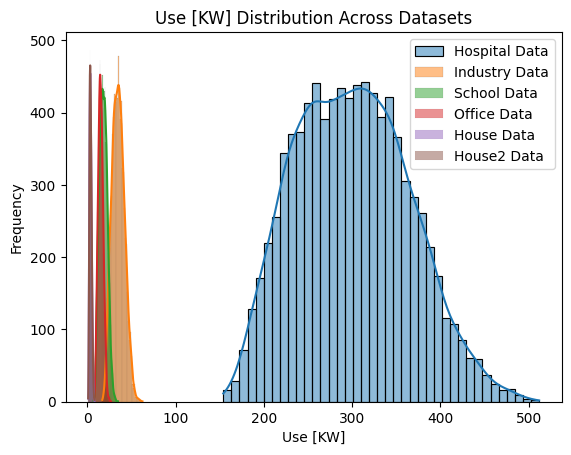

In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load datasets
df1 = pd.read_csv("Hospital_data.csv")
df2 = pd.read_csv("Industry_data.csv")
df3 = pd.read_csv("School_data.csv")
df4 = pd.read_csv("Office_data.csv")
df5 = pd.read_csv("House1_data.csv")
df6 = pd.read_csv("House2_data.csv")

# Plot the distribution of 'Use [KW]' for each dataset
for dataset, label in [(df1, "Hospital Data"), (df2, "Industry Data"), (df3, "School Data"), (df4, "Office Data"), (df5, "House Data"), (df6, "House2 Data")]:
    sns.histplot(dataset["Use [kW]"], kde=True, label=label)

# Add legend and title
plt.legend()
plt.title("Use [KW] Distribution Across Datasets")
plt.xlabel("Use [KW]")
plt.ylabel("Frequency")
plt.show()
